# Partea a treia. Transformer baseline
- la nivel de text, titlu, propozitie, summary. (?)

In [1]:
import pandas as pd
import re
from collections import Counter
from sklearn.preprocessing import StandardScaler, LabelEncoder
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer
import torch.nn as nn
from transformers import AutoModel
from transformers import get_linear_schedule_with_warmup
from torch.optim import AdamW
from sklearn.metrics import f1_score
import torch
import numpy as np
import random

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import unicodedata
import json
import os


In [2]:
# FUNCTII UTILE le definim sus
def drop_columns(df, columns_to_drop):
    return df.drop(columns=columns_to_drop)

# avem o problema la moldova
# diacriticele aparent nu sunt unicode?
def clean_text(text):
    if not isinstance(text, str):
        return ""
    
    text = unicodedata.normalize("NFC", text)

    # remove combining chars, deci t de la tap nu va mai avea caciulita sepaarata va fi un singur char
    text = ''.join(c for c in text if not unicodedata.combining(c))

    text = text.replace("„", '"').replace("”", '"')
    text = text.replace("’", "'")

    # remove control chars
    text = ''.join(c for c in text if unicodedata.category(c)[0] != 'C')

    text = text.replace("\n", " ")
    text = text.replace('""', '"')
    text = re.sub(r"\s+", " ", text)
        
    return text.strip()


def count_unk(texts, tokenizer, n=100):
    total_unk = 0
    total_tokens = 0

    for t in texts[:n]:
        enc = tokenizer(
            t,
            truncation=True,
            max_length=512
        )

        input_ids = enc["input_ids"]
        total_tokens += len(input_ids)

        unk_id = tokenizer.unk_token_id
        total_unk += sum(1 for x in input_ids if x == unk_id)

    return total_unk / total_tokens


def count_unk_absolute(texts, tokenizer, n=100):
    total_unk = 0
    for t in texts[:n]:
        enc = tokenizer(t, truncation=True, max_length=512)
        unk_id = tokenizer.unk_token_id
        total_unk += sum(1 for x in enc["input_ids"] if x == unk_id)
    return total_unk


def count_combining(texts, n=1000):
    count = 0
    for t in texts[:n]:
        if any(unicodedata.combining(c) for c in t):
            count += 1
    return count


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

In [3]:
# variabile globale
tokenizer = AutoTokenizer.from_pretrained("dumitrescustefan/bert-base-romanian-cased-v1")
# asta o pun sus
EPOCHS      = 6
LR          = 2e-5
OUTPUT_DIR  = "outputs_transformer_baseline"

In [4]:
# R1
# Pas 4 dataset cu sliding window

class AuthorDataset(Dataset):
    def __init__(self, texts, labels, tokenizer,
                 max_length=512, overlap=0.1):
        self.texts      = texts
        self.labels     = labels
        self.tokenizer  = tokenizer
        self.max_length = max_length
        self.stride     = int(max_length * (1 - overlap))  # 460


    def __len__(self):
        return len(self.texts)


    def __getitem__(self, idx):
        text  = self.texts[idx]
        label = self.labels[idx]

        # tokenizam fara truncation ca sa vedem lungimea reala
        tokens = self.tokenizer(
            text,
            truncation=False,
            add_special_tokens=True,
            return_tensors='pt'
        )
        input_ids = tokens['input_ids'][0]

        # daca e scurt - o singura fereastra
        if len(input_ids) <= self.max_length:
            encoded = self.tokenizer(
                text,
                max_length=self.max_length,
                padding='max_length',
                truncation=True,
                return_tensors='pt'
            )
            return {
                'input_ids':      encoded['input_ids'].squeeze(0),
                'attention_mask': encoded['attention_mask'].squeeze(0),
                'label':          torch.tensor(label, dtype=torch.long),
                'n_windows':      torch.tensor(1, dtype=torch.long)
            }

        # daca e lung - luam prima fereastra pentru training
        # (la inferenta folosim toate ferestrele cu voting)
        input_ids_window = input_ids[:self.max_length]
        attention_mask   = torch.ones(self.max_length, dtype=torch.long)

        return {
            'input_ids':      input_ids_window,
            'attention_mask': attention_mask,
            'label':          torch.tensor(label, dtype=torch.long),
            'n_windows':      torch.tensor(
                (len(input_ids) // self.stride) + 1,
                dtype=torch.long
            )
        }

In [5]:
# # Pas 4 cream dataloaderle
# BATCH_SIZE = 8  # mic din cauza RAM GPU

# # si aici la random shuffle trebuie activat seed
# generator = torch.Generator()
# generator.manual_seed(42)

# train_dataset = AuthorDataset(texts_train_t20ro, y_train_t20ro, tokenizer)
# val_dataset   = AuthorDataset(texts_val_t20ro,   y_val_t20ro,   tokenizer)
# test_dataset  = AuthorDataset(texts_test_t20ro,  y_test_t20ro,  tokenizer)

# train_loader = DataLoader(
#     train_dataset,
#     batch_size=BATCH_SIZE,
#     shuffle=True,
#     num_workers=4,
#     pin_memory=True,
#     generator=generator
# )
# val_loader = DataLoader(
#     val_dataset,
#     batch_size=BATCH_SIZE,
#     shuffle=False,
#     num_workers=4,
#     pin_memory=True,
#     generator=generator
# )
# test_loader = DataLoader(
#     test_dataset,
#     batch_size=BATCH_SIZE,
#     shuffle=False,
#     num_workers=4,
#     pin_memory=True,
#     generator=generator
# )

# print(f"Train batches: {len(train_loader)}")
# print(f"Val batches:   {len(val_loader)}")

In [6]:
# R2
# Pas 5 Modelul efectiv si forward pass
class BaselineBERT(nn.Module):
    def __init__(self, num_authors, dropout=0.2):
        super().__init__()
        self.bert = AutoModel.from_pretrained(
            "dumitrescustefan/bert-base-romanian-cased-v1"
        )
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(768, num_authors)

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask
        )
        cls_output = outputs.last_hidden_state[:, 0, :]  # CLS token
        cls_output = self.dropout(cls_output)
        logits     = self.classifier(cls_output)
        return logits

In [7]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device {device}")

Device cuda


In [8]:
# R3
def train_epoch(model, loader, optimizer, scheduler, criterion, device):
    model.train()
    total_loss = 0.0

    for i, batch in enumerate(loader):
        input_ids = batch['input_ids'].to(device, non_blocking=True) # transfer asincron la CPU a batchului urmator 
        attention_mask = batch['attention_mask'].to(device, non_blocking=True)
        labels = batch['label'].to(device, non_blocking=True)

        # init gradienti cu 0
        optimizer.zero_grad(set_to_none=True) # setam pe None ca e mai rapid
        logits = model(input_ids, attention_mask)
        loss = criterion(logits,labels)

        # asta a fost forward pass
        # acum backprop ca sa setam weights
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()

        total_loss += loss.item()

        if i % 100 == 0:
            print(f"  Batch {i}/{len(loader)} loss: {loss.item():.4f}")

    return total_loss / len(loader)

def eval_epoch(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    all_preds  = []
    all_labels = []

    with torch.no_grad():
        for batch in loader:
            input_ids      = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels         = batch['label'].to(device)

            logits = model(input_ids, attention_mask)
            loss   = criterion(logits, labels)

            preds = torch.argmax(logits, dim=-1)

            total_loss  += loss.item()
            all_preds   .extend(preds.cpu().numpy())
            all_labels  .extend(labels.cpu().numpy())

    f1 = f1_score(all_labels, all_preds, average='macro')
    accuracy = (np.array(all_preds) == np.array(all_labels)).mean()
    return total_loss / len(loader), f1, accuracy


def predict_with_voting(model, text, tokenizer,
                         max_length=512, overlap=0.1, device='cuda'):
    stride = int(max_length * (1 - overlap))
    model.eval()

    tokens = tokenizer(
        text, truncation=False,
        add_special_tokens=True, return_tensors='pt'
    )
    input_ids = tokens['input_ids'][0]

    predictions = []

    with torch.no_grad():
        for start in range(0, len(input_ids), stride):
            end      = min(start + max_length, len(input_ids))
            window   = input_ids[start:end]

            # padding
            if len(window) < max_length:
                padding = torch.zeros(max_length - len(window), dtype=torch.long)
                window  = torch.cat([window, padding])

            attn_mask = (window != 0).long()

            logits = model(
                window.unsqueeze(0).to(device),
                attn_mask.unsqueeze(0).to(device)
            )
            pred = torch.argmax(logits, dim=-1).item()
            predictions.append(pred)

            if end == len(input_ids):
                break

    return Counter(predictions).most_common(1)[0][0]

In [9]:
# # training loop
# best_f1 = 0
# train_losses = []
# val_losses = []
# val_f1_scores = []
# val_accuracies = []

# train_f1_scores = []
# train_accuracies = []

# for epoch in range(EPOCHS):
#     print(f"\nEpoch {epoch+1}/{EPOCHS}")

#     train_loss = train_epoch(
#         model, train_loader, optimizer, scheduler, criterion, device
#     )
#     # scoatem scorurile din epoca respectiva
#     _, train_f1, train_acc = eval_epoch(model, train_loader, criterion, device)
#     train_losses.append(train_loss)
#     train_f1_scores.append(train_f1)
#     train_accuracies.append(train_acc)

#     val_loss, val_f1, val_acc = eval_epoch(model, val_loader, criterion, device)
#     val_losses.append(val_loss)
#     val_f1_scores.append(val_f1)
#     val_accuracies.append(val_acc)

#     print(f"Train loss: {train_loss:.4f} | Train F1: {train_f1:.4f} | Train Accuracy: {train_acc:.4f}")
#     print(f"Val loss:   {val_loss:.4f}  |  Val F1: {val_f1:.4f} | Val Accuracy: {val_acc:.4f}")

#     # salvezi cel mai bun model
#     if val_f1 > best_f1:
#         best_f1 = val_f1
#         torch.save(model.state_dict(), 'best_model_ro_top20.pt')
#         print(f"  Model salvat (F1={val_f1:.4f})")

# print(f"\nBest Val F1: {best_f1:.4f}")
# # 155 minute F1 la a treia epoca 0.6654 !!!

# # Epoch 1/4
# #   Batch 0/3106 loss: 3.1662
# #   Batch 100/3106 loss: 2.8325
# #   Batch 200/3106 loss: 2.8588
# # cu seed si aia de dnn pe true 177 


### Training Progress Plots

Pe fep am testat cu 6 epoci pe acelasi dataset (top20 ro) si acestea sunt rezultatele

Epoch 1/6
  Batch 0/6212 loss: 3.3398
  Batch 100/6212 loss: 3.0172
  Batch 200/6212 loss: 2.9958
  Batch 300/6212 loss: 2.8807
  Batch 400/6212 loss: 2.3121
  Batch 500/6212 loss: 2.2705
  Batch 600/6212 loss: 2.1333
  Batch 700/6212 loss: 3.3909
  Batch 800/6212 loss: 2.2963
  Batch 900/6212 loss: 2.2671
  Batch 1000/6212 loss: 2.6085
  Batch 1100/6212 loss: 1.8103
  Batch 1200/6212 loss: 1.6059
  Batch 1300/6212 loss: 1.6104
  Batch 1400/6212 loss: 1.5891
  Batch 1500/6212 loss: 1.6329
  Batch 1600/6212 loss: 1.5971
  Batch 1700/6212 loss: 2.6307
  Batch 1800/6212 loss: 1.6265
  Batch 1900/6212 loss: 1.6632
  Batch 2000/6212 loss: 1.4546
  Batch 2100/6212 loss: 1.7348
  Batch 2200/6212 loss: 1.3223
  Batch 2300/6212 loss: 1.6112
  Batch 2400/6212 loss: 1.2106
  Batch 2500/6212 loss: 2.6864
  Batch 2600/6212 loss: 1.9290
  Batch 2700/6212 loss: 1.0743
  Batch 2800/6212 loss: 1.7954
  Batch 2900/6212 loss: 1.6169
  Batch 3000/6212 loss: 1.4820
  Batch 3100/6212 loss: 1.4980
  Batch 3200/6212 loss: 2.2994
  Batch 3300/6212 loss: 1.5763
  Batch 3400/6212 loss: 1.3877
  Batch 3500/6212 loss: 1.5101
  Batch 3600/6212 loss: 1.0329
  Batch 3700/6212 loss: 1.4725
  Batch 3800/6212 loss: 0.4057
  Batch 3900/6212 loss: 1.4657
  Batch 4000/6212 loss: 0.7616
  Batch 4100/6212 loss: 1.1447
  Batch 4200/6212 loss: 1.0617
  Batch 4300/6212 loss: 0.8815
  Batch 4400/6212 loss: 1.4018
  Batch 4500/6212 loss: 1.8396
  Batch 4600/6212 loss: 1.0650
  Batch 4700/6212 loss: 1.6276
  Batch 4800/6212 loss: 1.9531
  Batch 4900/6212 loss: 1.9510
  Batch 5000/6212 loss: 1.1164
  Batch 5100/6212 loss: 2.1329
  Batch 5200/6212 loss: 1.6334
  Batch 5300/6212 loss: 1.8488
  Batch 5400/6212 loss: 1.8458
  Batch 5500/6212 loss: 1.2088
  Batch 5600/6212 loss: 1.6173
  Batch 5700/6212 loss: 1.1984
  Batch 5800/6212 loss: 1.0577
  Batch 5900/6212 loss: 1.5308
  Batch 6000/6212 loss: 1.0816
  Batch 6100/6212 loss: 0.3736
  Batch 6200/6212 loss: 2.1331
Train loss: 1.7154 | Train F1: 0.6515 | Train Accuracy: 0.6588
Val loss:   1.3073  |  Val F1: 0.6103 | Val Accuracy: 0.6067
  Model salvat (F1=0.6103)

Epoch 2/6
  Batch 0/6212 loss: 1.3450
  Batch 100/6212 loss: 1.6902
  Batch 200/6212 loss: 1.1084
  Batch 300/6212 loss: 0.4102
  Batch 400/6212 loss: 2.1095
  Batch 500/6212 loss: 0.9531
  Batch 600/6212 loss: 0.7733
  Batch 700/6212 loss: 0.3003
  Batch 800/6212 loss: 1.3582
  Batch 900/6212 loss: 0.6165
  Batch 1000/6212 loss: 1.3974
  Batch 1100/6212 loss: 1.4732
  Batch 1200/6212 loss: 0.5478
  Batch 1300/6212 loss: 0.9244
  Batch 1400/6212 loss: 1.5514
  Batch 1500/6212 loss: 1.2353
  Batch 1600/6212 loss: 0.9927
  Batch 1700/6212 loss: 1.5814
  Batch 1800/6212 loss: 0.9707
  Batch 1900/6212 loss: 0.3931
  Batch 2000/6212 loss: 1.2219
  Batch 2100/6212 loss: 0.2367
  Batch 2200/6212 loss: 1.0487
  Batch 2300/6212 loss: 0.8145
  Batch 2400/6212 loss: 0.4622
  Batch 2500/6212 loss: 1.1116
  Batch 2600/6212 loss: 1.3454
  Batch 2700/6212 loss: 0.4799
  Batch 2800/6212 loss: 0.8665
  Batch 2900/6212 loss: 0.9101
  Batch 3000/6212 loss: 2.1467
  Batch 3100/6212 loss: 1.4540
  Batch 3200/6212 loss: 2.1550
  Batch 3300/6212 loss: 0.6713
  Batch 3400/6212 loss: 0.5946
  Batch 3500/6212 loss: 1.0482
  Batch 3600/6212 loss: 1.3695
  Batch 3700/6212 loss: 0.7424
  Batch 3800/6212 loss: 1.3175
  Batch 3900/6212 loss: 2.1189
  Batch 4000/6212 loss: 0.5140
  Batch 4100/6212 loss: 0.5956
  Batch 4200/6212 loss: 0.7115
  Batch 4300/6212 loss: 0.5888
  Batch 4400/6212 loss: 0.5682
  Batch 4500/6212 loss: 1.5157
  Batch 4600/6212 loss: 0.5648
  Batch 4700/6212 loss: 0.8975
  Batch 4800/6212 loss: 1.1633
  Batch 4900/6212 loss: 1.2036
  Batch 5000/6212 loss: 1.3383
  Batch 5100/6212 loss: 1.9977
  Batch 5200/6212 loss: 1.1267
  Batch 5300/6212 loss: 1.2810
  Batch 5400/6212 loss: 1.8942
  Batch 5500/6212 loss: 0.9461
  Batch 5600/6212 loss: 1.3318
  Batch 5700/6212 loss: 0.6270
  Batch 5800/6212 loss: 0.6594
  Batch 5900/6212 loss: 1.2317
  Batch 6000/6212 loss: 1.4221
  Batch 6100/6212 loss: 1.3833
  Batch 6200/6212 loss: 0.6951
Train loss: 1.0885 | Train F1: 0.7766 | Train Accuracy: 0.7760
Val loss:   1.1820  |  Val F1: 0.6364 | Val Accuracy: 0.6358
  Model salvat (F1=0.6364)

Epoch 3/6
  Batch 0/6212 loss: 0.4366
  Batch 100/6212 loss: 0.4320
  Batch 200/6212 loss: 1.2397
  Batch 300/6212 loss: 1.2197
  Batch 400/6212 loss: 1.2215
  Batch 500/6212 loss: 1.4327
  Batch 600/6212 loss: 1.2085
  Batch 700/6212 loss: 0.7239
  Batch 800/6212 loss: 1.1994
  Batch 900/6212 loss: 1.0730
  Batch 1000/6212 loss: 0.9623
  Batch 1100/6212 loss: 1.5190
  Batch 1200/6212 loss: 0.3523
  Batch 1300/6212 loss: 1.2904
  Batch 1400/6212 loss: 0.5150
  Batch 1500/6212 loss: 1.1846
  Batch 1600/6212 loss: 0.8881
  Batch 1700/6212 loss: 1.0147
  Batch 1800/6212 loss: 0.3573
  Batch 1900/6212 loss: 0.8778
  Batch 2000/6212 loss: 0.7296
  Batch 2100/6212 loss: 0.8636
  Batch 2200/6212 loss: 0.4884
  Batch 2300/6212 loss: 0.2322
  Batch 2400/6212 loss: 0.5314
  Batch 2500/6212 loss: 1.5037
  Batch 2600/6212 loss: 0.7869
  Batch 2700/6212 loss: 0.3334
  Batch 2800/6212 loss: 0.8563
  Batch 2900/6212 loss: 0.5387
  Batch 3000/6212 loss: 0.9857
  Batch 3100/6212 loss: 0.6133
  Batch 3200/6212 loss: 0.9537
  Batch 3300/6212 loss: 0.9595
  Batch 3400/6212 loss: 0.1469
  Batch 3500/6212 loss: 0.5151
  Batch 3600/6212 loss: 0.9170
  Batch 3700/6212 loss: 1.1667
  Batch 3800/6212 loss: 1.6561
  Batch 3900/6212 loss: 1.1777
  Batch 4000/6212 loss: 1.1628
  Batch 4100/6212 loss: 0.5118
  Batch 4200/6212 loss: 1.6415
  Batch 4300/6212 loss: 0.6643
  Batch 4400/6212 loss: 1.1187
  Batch 4500/6212 loss: 0.8062
  Batch 4600/6212 loss: 1.5690
  Batch 4700/6212 loss: 0.5751
  Batch 4800/6212 loss: 0.8110
  Batch 4900/6212 loss: 0.2656
  Batch 5000/6212 loss: 1.2533
  Batch 5100/6212 loss: 1.0789
  Batch 5200/6212 loss: 0.6912
  Batch 5300/6212 loss: 0.2114
  Batch 5400/6212 loss: 0.9682
  Batch 5500/6212 loss: 0.1775
  Batch 5600/6212 loss: 0.9591
  Batch 5700/6212 loss: 2.5871
  Batch 5800/6212 loss: 0.7537
  Batch 5900/6212 loss: 0.8273
  Batch 6000/6212 loss: 0.5245
  Batch 6100/6212 loss: 0.7529
  Batch 6200/6212 loss: 0.7302
Train loss: 0.7611 | Train F1: 0.8700 | Train Accuracy: 0.8718
Val loss:   1.2121  |  Val F1: 0.6617 | Val Accuracy: 0.6619
  Model salvat (F1=0.6617)

Epoch 4/6
  Batch 0/6212 loss: 0.1298
  Batch 100/6212 loss: 0.8435
  Batch 200/6212 loss: 0.5523
  Batch 300/6212 loss: 0.5171
  Batch 400/6212 loss: 0.5087
  Batch 500/6212 loss: 0.6661
  Batch 600/6212 loss: 0.2748
  Batch 700/6212 loss: 0.7319
  Batch 800/6212 loss: 1.3457
  Batch 900/6212 loss: 1.6547
  Batch 1000/6212 loss: 0.2769
  Batch 1100/6212 loss: 0.3614
  Batch 1200/6212 loss: 0.1311
  Batch 1300/6212 loss: 0.6063
  Batch 1400/6212 loss: 0.2471
  Batch 1500/6212 loss: 0.4430
  Batch 1600/6212 loss: 0.8007
  Batch 1700/6212 loss: 0.2730
  Batch 1800/6212 loss: 0.3922
  Batch 1900/6212 loss: 0.5399
  Batch 2000/6212 loss: 0.6159
  Batch 2100/6212 loss: 0.6549
  Batch 2200/6212 loss: 0.4402
  Batch 2300/6212 loss: 0.5395
  Batch 2400/6212 loss: 0.4981
  Batch 2500/6212 loss: 0.7686
  Batch 2600/6212 loss: 0.2463
  Batch 2700/6212 loss: 0.1109
  Batch 2800/6212 loss: 0.1568
  Batch 2900/6212 loss: 0.1454
  Batch 3000/6212 loss: 0.5621
  Batch 3100/6212 loss: 0.1558
  Batch 3200/6212 loss: 0.3854
  Batch 3300/6212 loss: 1.6488
  Batch 3400/6212 loss: 0.6616
  Batch 3500/6212 loss: 0.3650
  Batch 3600/6212 loss: 0.2675
  Batch 3700/6212 loss: 1.0902
  Batch 3800/6212 loss: 0.5620
  Batch 3900/6212 loss: 0.6558
  Batch 4000/6212 loss: 0.5807
  Batch 4100/6212 loss: 0.1294
  Batch 4200/6212 loss: 0.4949
  Batch 4300/6212 loss: 0.9598
  Batch 4400/6212 loss: 0.1920
  Batch 4500/6212 loss: 0.2756
  Batch 4600/6212 loss: 0.6300
  Batch 4700/6212 loss: 0.7211
  Batch 4800/6212 loss: 0.1906
  Batch 4900/6212 loss: 0.1311
  Batch 5000/6212 loss: 0.6874
  Batch 5100/6212 loss: 0.5717
  Batch 5200/6212 loss: 0.4929
  Batch 5300/6212 loss: 0.0850
  Batch 5400/6212 loss: 0.7825
  Batch 5500/6212 loss: 0.9721
  Batch 5600/6212 loss: 0.3150
  Batch 5700/6212 loss: 0.0299
  Batch 5800/6212 loss: 0.0654
  Batch 5900/6212 loss: 0.0777
  Batch 6000/6212 loss: 0.4397
  Batch 6100/6212 loss: 0.6861
  Batch 6200/6212 loss: 0.9581
Train loss: 0.4899 | Train F1: 0.9306 | Train Accuracy: 0.9309
Val loss:   1.3709  |  Val F1: 0.6655 | Val Accuracy: 0.6582
  Model salvat (F1=0.6655)

Epoch 5/6
  Batch 0/6212 loss: 0.4804
  Batch 100/6212 loss: 0.2563
  Batch 200/6212 loss: 0.7660
  Batch 300/6212 loss: 0.2469
  Batch 400/6212 loss: 0.3353
  Batch 500/6212 loss: 0.2780
  Batch 600/6212 loss: 0.1902
  Batch 700/6212 loss: 0.0394
  Batch 800/6212 loss: 0.1414
  Batch 900/6212 loss: 0.1521
  Batch 1000/6212 loss: 0.5407
  Batch 1100/6212 loss: 0.0954
  Batch 1200/6212 loss: 0.2954
  Batch 1300/6212 loss: 0.1683
  Batch 1400/6212 loss: 0.0854
  Batch 1500/6212 loss: 0.8022
  Batch 1600/6212 loss: 0.6664
  Batch 1700/6212 loss: 0.9567
  Batch 1800/6212 loss: 0.0696
  Batch 1900/6212 loss: 0.1564
  Batch 2000/6212 loss: 0.3743
  Batch 2100/6212 loss: 0.0657
  Batch 2200/6212 loss: 0.0561
  Batch 2300/6212 loss: 0.1442
  Batch 2400/6212 loss: 0.0774
  Batch 2500/6212 loss: 0.0665
  Batch 2600/6212 loss: 0.0134
  Batch 2700/6212 loss: 0.0823
  Batch 2800/6212 loss: 0.1410
  Batch 2900/6212 loss: 0.0286
  Batch 3000/6212 loss: 0.1551
  Batch 3100/6212 loss: 0.2142
  Batch 3200/6212 loss: 0.6717
  Batch 3300/6212 loss: 0.0338
  Batch 3400/6212 loss: 0.0639
  Batch 3500/6212 loss: 1.2588
  Batch 3600/6212 loss: 0.6396
  Batch 3700/6212 loss: 0.3692
  Batch 3800/6212 loss: 0.3508
  Batch 3900/6212 loss: 0.7124
  Batch 4000/6212 loss: 0.6027
  Batch 4100/6212 loss: 0.0816
  Batch 4200/6212 loss: 0.1228
  Batch 4300/6212 loss: 0.5223
  Batch 4400/6212 loss: 0.1241
  Batch 4500/6212 loss: 0.0682
  Batch 4600/6212 loss: 0.2215
  Batch 4700/6212 loss: 0.4314
  Batch 4800/6212 loss: 0.0109
  Batch 4900/6212 loss: 0.0254
  Batch 5000/6212 loss: 0.2091
  Batch 5100/6212 loss: 0.0235
  Batch 5200/6212 loss: 0.0451
  Batch 5300/6212 loss: 0.2995
  Batch 5400/6212 loss: 0.6732
  Batch 5500/6212 loss: 0.0946
  Batch 5600/6212 loss: 1.3506
  Batch 5700/6212 loss: 0.5508
  Batch 5800/6212 loss: 0.6842
  Batch 5900/6212 loss: 0.0065
  Batch 6000/6212 loss: 0.0740
  Batch 6100/6212 loss: 0.0391
  Batch 6200/6212 loss: 0.6752
Train loss: 0.2884 | Train F1: 0.9657 | Train Accuracy: 0.9673
Val loss:   1.5627  |  Val F1: 0.6740 | Val Accuracy: 0.6687
  Model salvat (F1=0.6740)

Epoch 6/6
  Batch 0/6212 loss: 0.1413
  Batch 100/6212 loss: 0.1225
  Batch 200/6212 loss: 0.1105
  Batch 300/6212 loss: 0.0035
  Batch 400/6212 loss: 0.0610
  Batch 500/6212 loss: 0.4611
  Batch 600/6212 loss: 0.1575
  Batch 700/6212 loss: 0.0087
  Batch 800/6212 loss: 0.0007
  Batch 900/6212 loss: 0.4271
  Batch 1000/6212 loss: 0.2162
  Batch 1100/6212 loss: 0.0735
  Batch 1200/6212 loss: 0.2635
  Batch 1300/6212 loss: 0.3806
  Batch 1400/6212 loss: 0.2227
  Batch 1500/6212 loss: 0.0238
  Batch 1600/6212 loss: 0.2748
  Batch 1700/6212 loss: 0.0119
  Batch 1800/6212 loss: 0.1370
  Batch 1900/6212 loss: 0.1170
  Batch 2000/6212 loss: 0.1763
  Batch 2100/6212 loss: 0.1540
  Batch 2200/6212 loss: 0.0122
  Batch 2300/6212 loss: 0.1022
  Batch 2400/6212 loss: 0.0117
  Batch 2500/6212 loss: 0.0113
  Batch 2600/6212 loss: 0.0145
  Batch 2700/6212 loss: 0.0646
  Batch 2800/6212 loss: 0.0105
  Batch 2900/6212 loss: 0.0070
  Batch 3000/6212 loss: 0.3033
  Batch 3100/6212 loss: 0.0036
  Batch 3200/6212 loss: 0.0014
  Batch 3300/6212 loss: 0.0048
  Batch 3400/6212 loss: 0.0083
  Batch 3500/6212 loss: 0.0110
  Batch 3600/6212 loss: 0.2047
  Batch 3700/6212 loss: 0.0236
  Batch 3800/6212 loss: 0.0119
  Batch 3900/6212 loss: 0.1098
  Batch 4000/6212 loss: 0.2267
  Batch 4100/6212 loss: 0.2434
  Batch 4200/6212 loss: 0.0041
  Batch 4300/6212 loss: 0.0050
  Batch 4400/6212 loss: 0.5168
  Batch 4500/6212 loss: 0.0163
  Batch 4600/6212 loss: 0.0342
  Batch 4700/6212 loss: 0.0332
  Batch 4800/6212 loss: 0.0695
  Batch 4900/6212 loss: 0.0109
  Batch 5000/6212 loss: 0.3685
  Batch 5100/6212 loss: 0.0396
  Batch 5200/6212 loss: 0.3527
  Batch 5300/6212 loss: 0.0272
  Batch 5400/6212 loss: 0.1313
  Batch 5500/6212 loss: 0.0010
  Batch 5600/6212 loss: 0.0370
  Batch 5700/6212 loss: 0.0063
  Batch 5800/6212 loss: 0.0194
  Batch 5900/6212 loss: 0.1421
  Batch 6000/6212 loss: 0.3289
  Batch 6100/6212 loss: 0.0008
  Batch 6200/6212 loss: 0.1061
Train loss: 0.1646 | Train F1: 0.9789 | Train Accuracy: 0.9800
Val loss:   1.7658  |  Val F1: 0.6563 | Val Accuracy: 0.6515

Best Val F1: 0.6740
                    precision    recall  f1-score   support

    Adrian Dumitru       0.73      0.75      0.74        77
Alexandra Andronie       0.51      0.67      0.58        46
  Alexandru Costea       0.82      0.59      0.69       100
  Alexandru Toader       0.74      0.83      0.78        30
     Alina Manaila       0.57      0.69      0.62        42
     Alina Popescu       0.43      0.50      0.46        48
   Andrada Giubega       0.84      0.78      0.81        41
    Andreea Tobias       0.72      0.72      0.72        29
    Bogdan Pacurar       0.71      0.67      0.69        96
   Daniela Chihaia       0.68      0.69      0.68        39
     Diana Nechita       0.80      0.78      0.79       110
  Georgiana Marina       0.69      0.64      0.66       127
       Ioana Coman       0.29      0.43      0.35        53
       Liviu Cojan       0.66      0.65      0.66       128
    Luana Pavaluca       0.78      0.72      0.75       102
       Marco Badea       0.54      0.61      0.57        33
      Mihnea Lazar       0.41      0.71      0.52        17
      Monica Bonea       0.73      0.66      0.69       105
       Robert Kiss       0.52      0.46      0.49        61
    Vlad Mironescu       0.67      0.63      0.65        35

          accuracy                           0.66      1319
         macro avg       0.64      0.66      0.65      1319
      weighted avg       0.68      0.66      0.66      1319

Job finished



Inainte de a trece mai departe voi defini niste functii ca sa ma ajute sa rulez selectiv nu neaparat toate celulele

In [10]:
# R4
# dataloader
def build_dataloaders(train_df, val_df, test_df, tokenizer, batch_size=8, seed=42):
    # labels
    le = LabelEncoder()
    le.fit(train_df['author'])

    y_train = le.transform(train_df['author'])
    y_val   = le.transform(val_df['author'])
    y_test  = le.transform(test_df['author'])

    num_authors = len(le.classes_)
    print(f"Numar autori: {num_authors}")
    print(f"Autori: {le.classes_}")

    # text
    texts_train = train_df['text'].tolist()
    texts_val   = val_df['text'].tolist()
    texts_test  = test_df['text'].tolist()

    print("\n[DEBUG] Combining chars BEFORE clean:")
    print("Train combining:", count_combining(texts_train))
    print("Val   combining:", count_combining(texts_val))
    print("Test  combining:", count_combining(texts_test))

    texts_train = train_df['text'].apply(clean_text).tolist()
    texts_val   = val_df['text'].apply(clean_text).tolist()
    texts_test  = test_df['text'].apply(clean_text).tolist()

    print("\n[DEBUG] UNK check:")
    print("Train UNK:", count_unk_absolute(texts_train, tokenizer))
    print("Val   UNK:", count_unk_absolute(texts_val, tokenizer))
    print("Test  UNK:", count_unk_absolute(texts_test, tokenizer))

    print("\n[DEBUG] Combining chars AFTER clean:")
    print("Train combining:", count_combining(texts_train))
    print("Val   combining:", count_combining(texts_val))
    print("Test  combining:", count_combining(texts_test))

    # datasets
    train_dataset = AuthorDataset(texts_train, y_train, tokenizer)
    val_dataset   = AuthorDataset(texts_val, y_val, tokenizer)
    test_dataset  = AuthorDataset(texts_test, y_test, tokenizer)

    # reproducibilitate
    generator = torch.Generator()
    generator.manual_seed(seed)

    # dataloaders
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4, pin_memory=True, generator=generator)
    val_loader   = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True, generator=generator)
    test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True, generator=generator)

    return train_loader, val_loader, test_loader, le, texts_test, y_test

In [11]:
# R5
def plot_training_curves(train_losses, val_losses,
                          train_f1s, val_f1s,
                          train_accs, val_accs,
                          dataset_name="", output_dir=""):
    epochs_range = range(1, len(train_losses) + 1)
    
    plt.figure(figsize=(18, 6))
    plt.suptitle(f'Training Progress — {dataset_name}', fontsize=14, y=1.02)
    
    # Loss
    plt.subplot(1, 3, 1)
    plt.plot(epochs_range, train_losses, label='Train Loss', marker='o', color='steelblue')
    plt.plot(epochs_range, val_losses,   label='Val Loss',   marker='o', color='coral')
    plt.title('Loss over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    
    # F1
    plt.subplot(1, 3, 2)
    plt.plot(epochs_range, train_f1s, label='Train F1', marker='o', color='blue')
    plt.plot(epochs_range, val_f1s,   label='Val F1',   marker='o', color='orange')
    plt.title('Macro F1 over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('F1 Score')
    plt.legend()
    plt.grid(True)
    
    # Accuracy
    plt.subplot(1, 3, 3)
    plt.plot(epochs_range, train_accs, label='Train Accuracy', marker='o', color='purple')
    plt.plot(epochs_range, val_accs,   label='Val Accuracy',   marker='o', color='green')
    plt.title('Accuracy over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)
    
    plt.tight_layout()
    plt.savefig(f'{output_dir}/training_curves_{dataset_name}.png', dpi=150, bbox_inches='tight')
    plt.show()


def plot_confusion_matrix_bert(y_true, y_pred, label_encoder,
                              dataset_name="", split='test', output_dir=""):

    labels = label_encoder.classes_
    n = len(labels)

    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    fig_size = max(12, n * 0.8)

    font_size = max(6, int(300 / n))

    # === COUNTS ===
    plt.figure(figsize=(fig_size, fig_size))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=labels,
        yticklabels=labels,
        annot_kws={"size": font_size},
        square=True,
        cbar=True
    )

    plt.title(f'Confusion Matrix (Counts) — {dataset_name} | {split}', fontsize=16)
    plt.xlabel('Predicted')
    plt.ylabel('True')

    plt.xticks(rotation=45, ha='right', fontsize=font_size)
    plt.yticks(rotation=0, fontsize=font_size)

    plt.tight_layout()
    plt.savefig(f'{output_dir}/cm_counts_{dataset_name}_{split}.png', dpi=150, bbox_inches='tight')
    plt.show()

    # === NORMALIZED ===
    plt.figure(figsize=(fig_size, fig_size))
    sns.heatmap(
        cm_norm,
        annot=True,
        fmt='.2f',
        cmap='Blues',
        xticklabels=labels,
        yticklabels=labels,
        annot_kws={"size": font_size},
        square=True,
        cbar=True,
        vmin=0,
        vmax=1
    )

    plt.title(f'Confusion Matrix (Normalized) — {dataset_name} | {split}', fontsize=16)
    plt.xlabel('Predicted')
    plt.ylabel('True')

    plt.xticks(rotation=45, ha='right', fontsize=font_size)
    plt.yticks(rotation=0, fontsize=font_size)

    plt.tight_layout()
    plt.savefig(f'{output_dir}/cm_norm_{dataset_name}_{split}.png', dpi=150, bbox_inches='tight')
    plt.show()

In [12]:
# R6
# train loop ca functie, tot aici am bagat optimiatorii si scheduler cu warmup si ce mai e
# si salvam si modelul
def run_transformer_experiment(train_loader, val_loader, 
                                num_labels, device, 
                                dataset_name="", epochs=EPOCHS, output_dir=""):
    set_seed(42)
    model = BaselineBERT(num_authors=num_labels).to(device)

    optimizer = AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)
    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=len(train_loader) // 10,
        num_training_steps=len(train_loader) * epochs
    )
    criterion = nn.CrossEntropyLoss()

    best_f1     = 0
    train_losses, val_losses = [], []
    train_f1s,   val_f1s    = [], []
    train_accs,  val_accs   = [], []
    model_path  = f'{output_dir}/best_model_{dataset_name}.pt'

    for epoch in range(epochs):
        print(f"\nEpoch {epoch+1}/{epochs}")

        train_loss = train_epoch(
            model, train_loader, optimizer, scheduler, criterion, device
        )
        _, train_f1, train_acc = eval_epoch(model, train_loader, criterion, device)
        val_loss, val_f1, val_acc = eval_epoch(model, val_loader, criterion, device)

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_f1s.append(train_f1)
        val_f1s.append(val_f1)
        train_accs.append(train_acc)
        val_accs.append(val_acc)

        print(f"Train loss: {train_loss:.4f} | F1: {train_f1:.4f} | Acc: {train_acc:.4f}")
        print(f"Val   loss: {val_loss:.4f}   | F1: {val_f1:.4f}   | Acc: {val_acc:.4f}")

        if val_f1 > best_f1:
            best_f1 = val_f1
            torch.save(model.state_dict(), model_path)
            print(f"  Salvat (F1={val_f1:.4f})")

    print(f"\nBest Val F1: {best_f1:.4f}")
    
    # # plot training curves
    # plot_training_curves(
    #     train_losses, val_losses,
    #     train_f1s, val_f1s,
    #     train_accs, val_accs,
    #     dataset_name=dataset_name
    # )
    # NU LE FACEM AICI
    return model, model_path, {
        'train_losses': train_losses, 'val_losses': val_losses,
        'train_f1s':    train_f1s,   'val_f1s':    val_f1s,
        'train_accs':   train_accs,  'val_accs':   val_accs,
        'best_val_f1':  best_f1
    }

In [13]:
def evaluate_with_voting(texts, y_true, tokenizer, 
                          label_encoder, device, dataset_name="", model_path=None):
    print(f"\nEvaluare cu majority voting pe test — {dataset_name}")

    if model_path is None:
        print("  Atentie: Nu s-a incarcat niciun model, se vor face predictii random!")
        exit(1)
    
    model = BaselineBERT(num_authors=len(label_encoder.classes_)).to(device)
    
    if model_path is not None:
        model.load_state_dict(torch.load(model_path, map_location=device))
        print(f"Incarcat best model din {model_path}")
    
    # scoatem predictiile
    all_preds = []
    for i, text in enumerate(texts):
        pred = predict_with_voting(model, text, tokenizer, device=device)
        all_preds.append(pred)
    
    f1  = f1_score(y_true, all_preds, average='macro')
    acc = (np.array(all_preds) == np.array(y_true)).mean()
    
    print(f"\nTest F1 macro: {f1:.4f} | Accuracy: {acc:.4f}")
    print(classification_report(
        y_true, all_preds,
        target_names=label_encoder.classes_
    ))
    
    return all_preds, f1, acc

# Pas5 Majority vote pe setul de test
# evaluezi pe test cu voting
# model.load_state_dict(torch.load('best_model_ro_top20.pt'))

# all_preds  = []
# all_labels = []

# for idx in range(len(texts_test_t20ro)):
#     pred  = predict_with_voting(model, texts_test_t20ro[idx], tokenizer, device=device)
#     all_preds.append(pred)
#     all_labels.append(y_test_t20ro[idx])

# print(classification_report(
#     all_labels, all_preds,
#     target_names=l_encoder.classes_
# ))

In [14]:
results = []

In [15]:
if OUTPUT_DIR:
    os.makedirs(OUTPUT_DIR, exist_ok=True)

### top 20 romania

In [17]:
# citim
top20_ro_train_text = pd.read_csv('final_stilo/top20_ro_train.csv')
top20_ro_val_text = pd.read_csv('final_stilo/top20_ro_val.csv')
top20_ro_test_text = pd.read_csv('final_stilo/top20_ro_test.csv')

In [19]:
train_loader_t20ro, val_loader_t20ro, test_loader_t20ro, label_encoder_t20ro, texts_test_t20ro, y_test_t20ro = build_dataloaders(
    top20_ro_train_text, top20_ro_val_text, top20_ro_test_text,
    tokenizer)

Numar autori: 20
Autori: ['Adrian Dumitru' 'Alexandra Andronie' 'Alexandru Costea'
 'Alexandru Toader' 'Alina Manaila' 'Alina Popescu' 'Andrada Giubega'
 'Andreea Tobias' 'Bogdan Pacurar' 'Daniela Chihaia' 'Diana Nechita'
 'Georgiana Marina' 'Ioana Coman' 'Liviu Cojan' 'Luana Pavaluca'
 'Marco Badea' 'Mihnea Lazar' 'Monica Bonea' 'Robert Kiss'
 'Vlad Mironescu']

[DEBUG] Combining chars BEFORE clean:
Train combining: 1
Val   combining: 1
Test  combining: 2

[DEBUG] UNK check:
Train UNK: 3
Val   UNK: 5
Test  UNK: 0

[DEBUG] Combining chars AFTER clean:
Train combining: 0
Val   combining: 0
Test  combining: 0


In [21]:
output_dir_1 = f'{OUTPUT_DIR}/top20_ro'
os.makedirs(output_dir_1, exist_ok=True)

In [ ]:
model_t20ro, model_path_t20ro, history_t20ro = run_transformer_experiment(
    train_loader_t20ro, val_loader_t20ro,
    num_labels=len(label_encoder_t20ro.classes_),
    device=device,
    dataset_name='top20_ro',
    epochs=EPOCHS, output_dir=output_dir_1
)
# 403 minute

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Epoch 1/6
  Batch 0/6212 loss: 2.8296
  Batch 100/6212 loss: 2.7709
  Batch 200/6212 loss: 2.9264
  Batch 300/6212 loss: 2.9206
  Batch 400/6212 loss: 2.9086
  Batch 500/6212 loss: 2.6779
  Batch 600/6212 loss: 2.7740
  Batch 700/6212 loss: 2.8419
  Batch 800/6212 loss: 1.8305
  Batch 900/6212 loss: 2.0152
  Batch 1000/6212 loss: 2.3045
  Batch 1100/6212 loss: 2.1265
  Batch 1200/6212 loss: 2.2217
  Batch 1300/6212 loss: 1.9420
  Batch 1400/6212 loss: 2.2486
  Batch 1500/6212 loss: 2.7305
  Batch 1600/6212 loss: 1.4542
  Batch 1700/6212 loss: 1.2593
  Batch 1800/6212 loss: 2.2725
  Batch 1900/6212 loss: 1.5747
  Batch 2000/6212 loss: 1.5789
  Batch 2100/6212 loss: 2.2900
  Batch 2200/6212 loss: 1.9616
  Batch 2300/6212 loss: 3.1877
  Batch 2400/6212 loss: 2.3993
  Batch 2500/6212 loss: 1.3509
  Batch 2600/6212 loss: 2.7404
  Batch 2700/6212 loss: 1.8055
  Batch 2800/6212 loss: 1.7974
  Batch 2900/6212 loss: 1.8401
  Batch 3000/6212 loss: 1.3381
  Batch 3100/6212 loss: 0.8085
  Batch 3

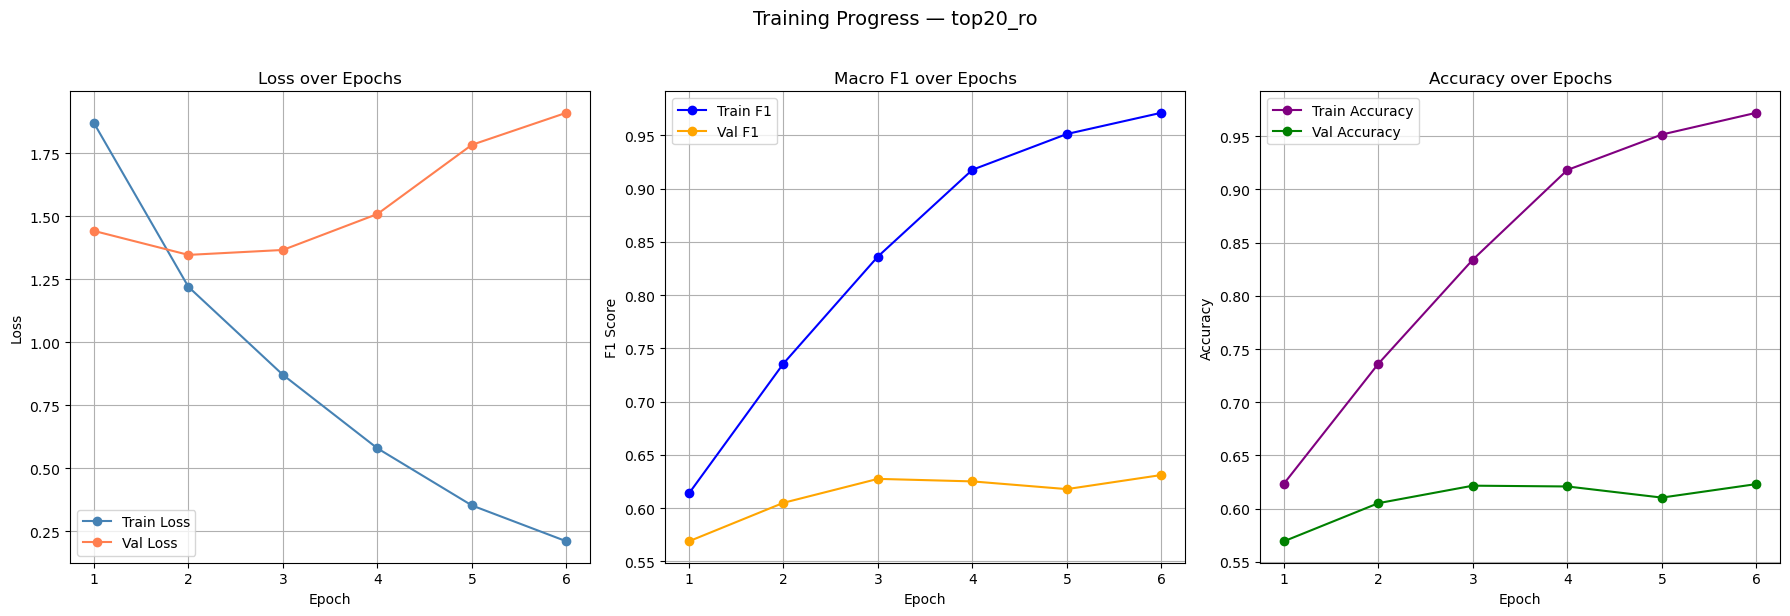

In [24]:
plot_training_curves(
    history_t20ro['train_losses'], history_t20ro['val_losses'],
    history_t20ro['train_f1s'],   history_t20ro['val_f1s'],
    history_t20ro['train_accs'],  history_t20ro['val_accs'],
    dataset_name='top20_ro', output_dir=output_dir_1
)

In [25]:
current_model_path = 'outputs_transformer_baseline/top20_ro/best_model_top20_ro.pt'

In [28]:
# ok o sa scoatem model_t20ro ca parametru
preds_t20ro, f1_t20ro, acc_t20ro = evaluate_with_voting(
    texts_test_t20ro, y_test_t20ro,
    tokenizer, label_encoder_t20ro, device, 
    dataset_name='top20_ro',
    model_path=current_model_path 
)


Evaluare cu majority voting pe test — top20_ro


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Incarcat best model din outputs_transformer_baseline/top20_ro/best_model_top20_ro.pt

Test F1 macro: 0.6247 | Accuracy: 0.6308
                    precision    recall  f1-score   support

    Adrian Dumitru       0.76      0.73      0.74        77
Alexandra Andronie       0.43      0.57      0.49        46
  Alexandru Costea       0.84      0.63      0.72       100
  Alexandru Toader       0.84      0.90      0.87        30
     Alina Manaila       0.57      0.57      0.57        42
     Alina Popescu       0.40      0.42      0.41        48
   Andrada Giubega       0.85      0.85      0.85        41
    Andreea Tobias       0.73      0.83      0.77        29
    Bogdan Pacurar       0.70      0.65      0.67        96
   Daniela Chihaia       0.67      0.67      0.67        39
     Diana Nechita       0.75      0.73      0.74       110
  Georgiana Marina       0.59      0.52      0.55       127
       Ioana Coman       0.22      0.36      0.28        53
       Liviu Cojan       0.66   

In [39]:
results.append({
    'Experiment': 'BERT Baseline',
    'dataset': 'top20_ro',
    'test_f1': round(f1_t20ro, 4),
    'test_acc': round(acc_t20ro, 4),
    'best val f1': round(history_t20ro['best_val_f1'], 4)  # best val f1
})

In [40]:
display(pd.DataFrame(results))

,Experiment,dataset,test_f1,test_acc,best val f1
0,BERT Baseline,top20_ro,0.6247,0.6308,0.6312


In [ ]:
output_file = f'{output_dir_1}/results.json'

# nu exista acum dar chiar daca e bagi cu append si iei ultimul
with open(output_file, 'w') as f:
    json.dump(results, f, indent=2)

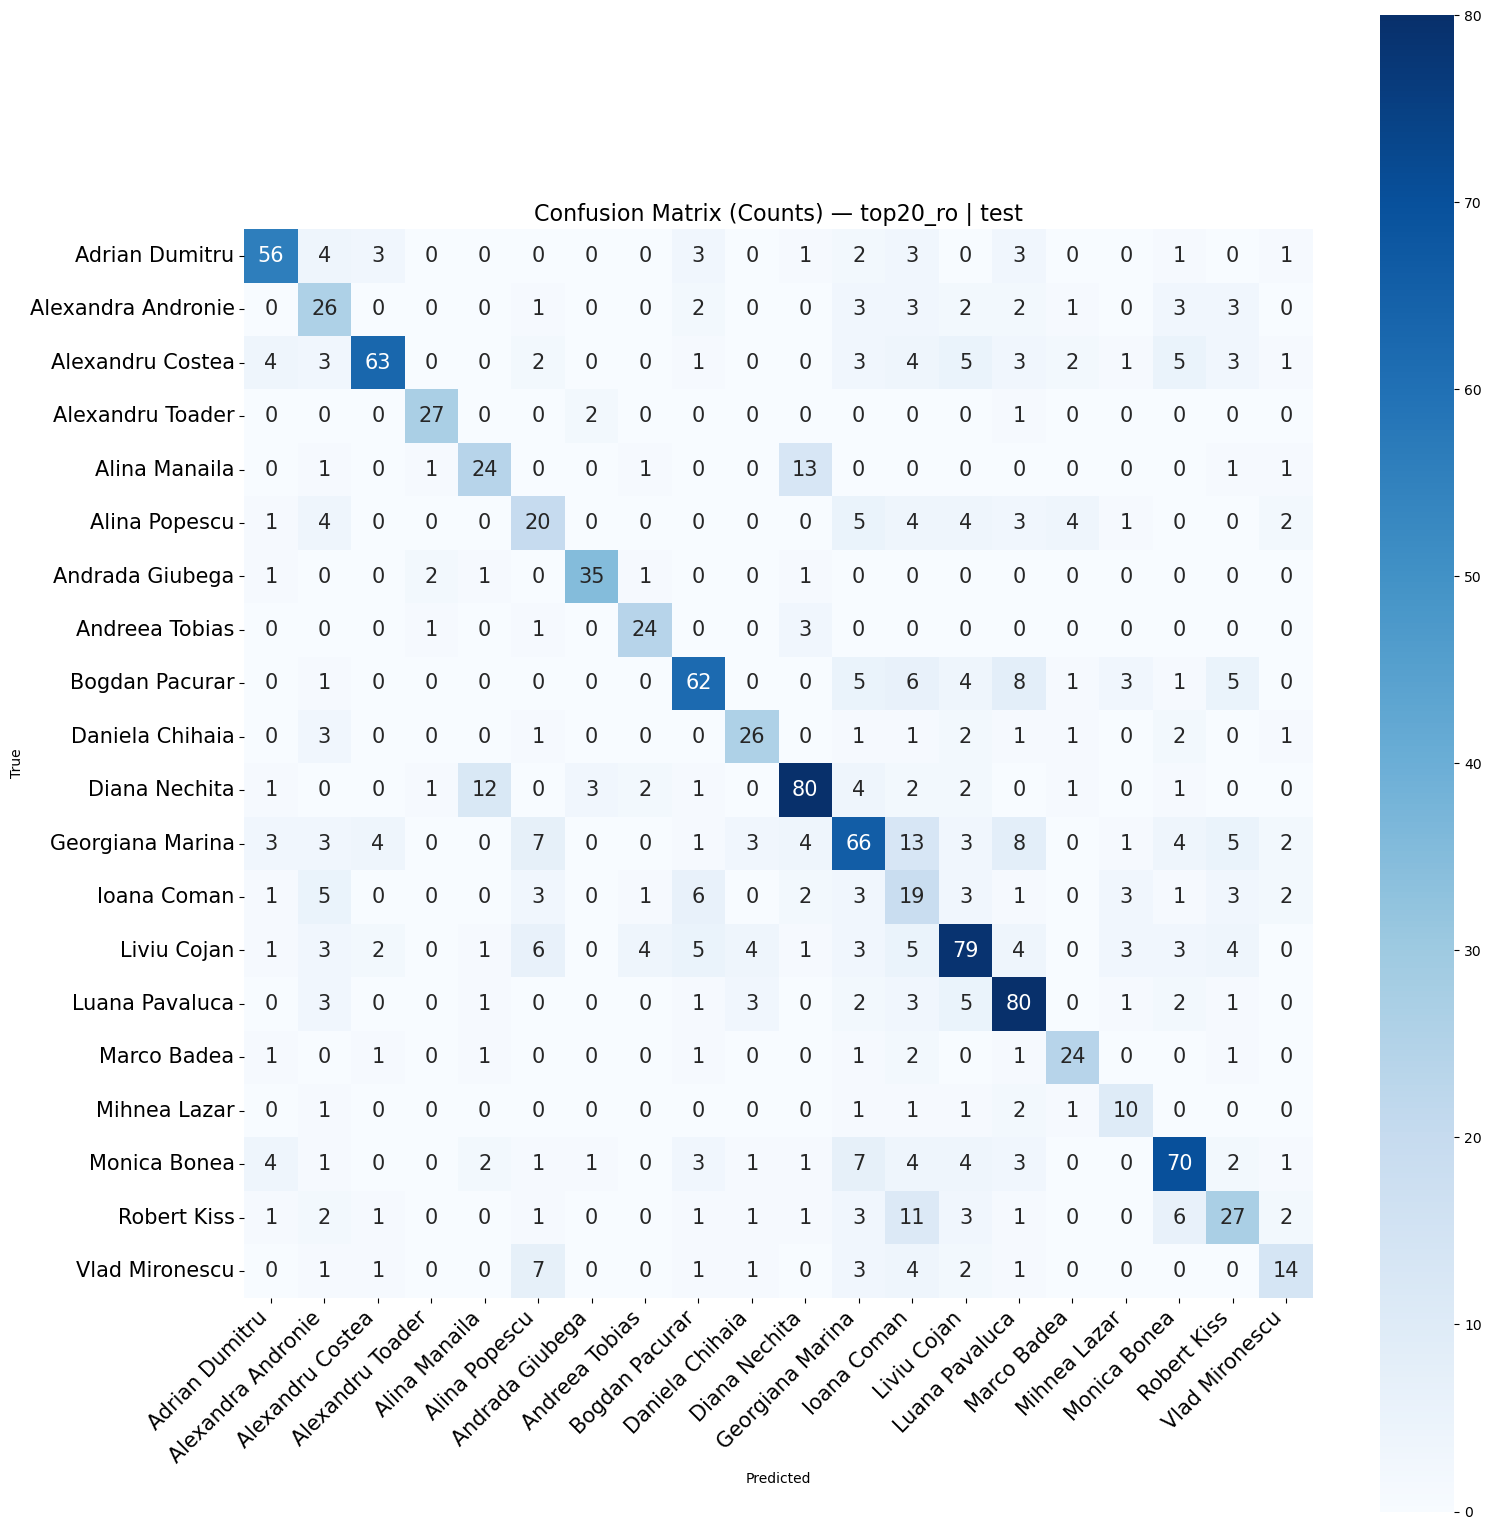

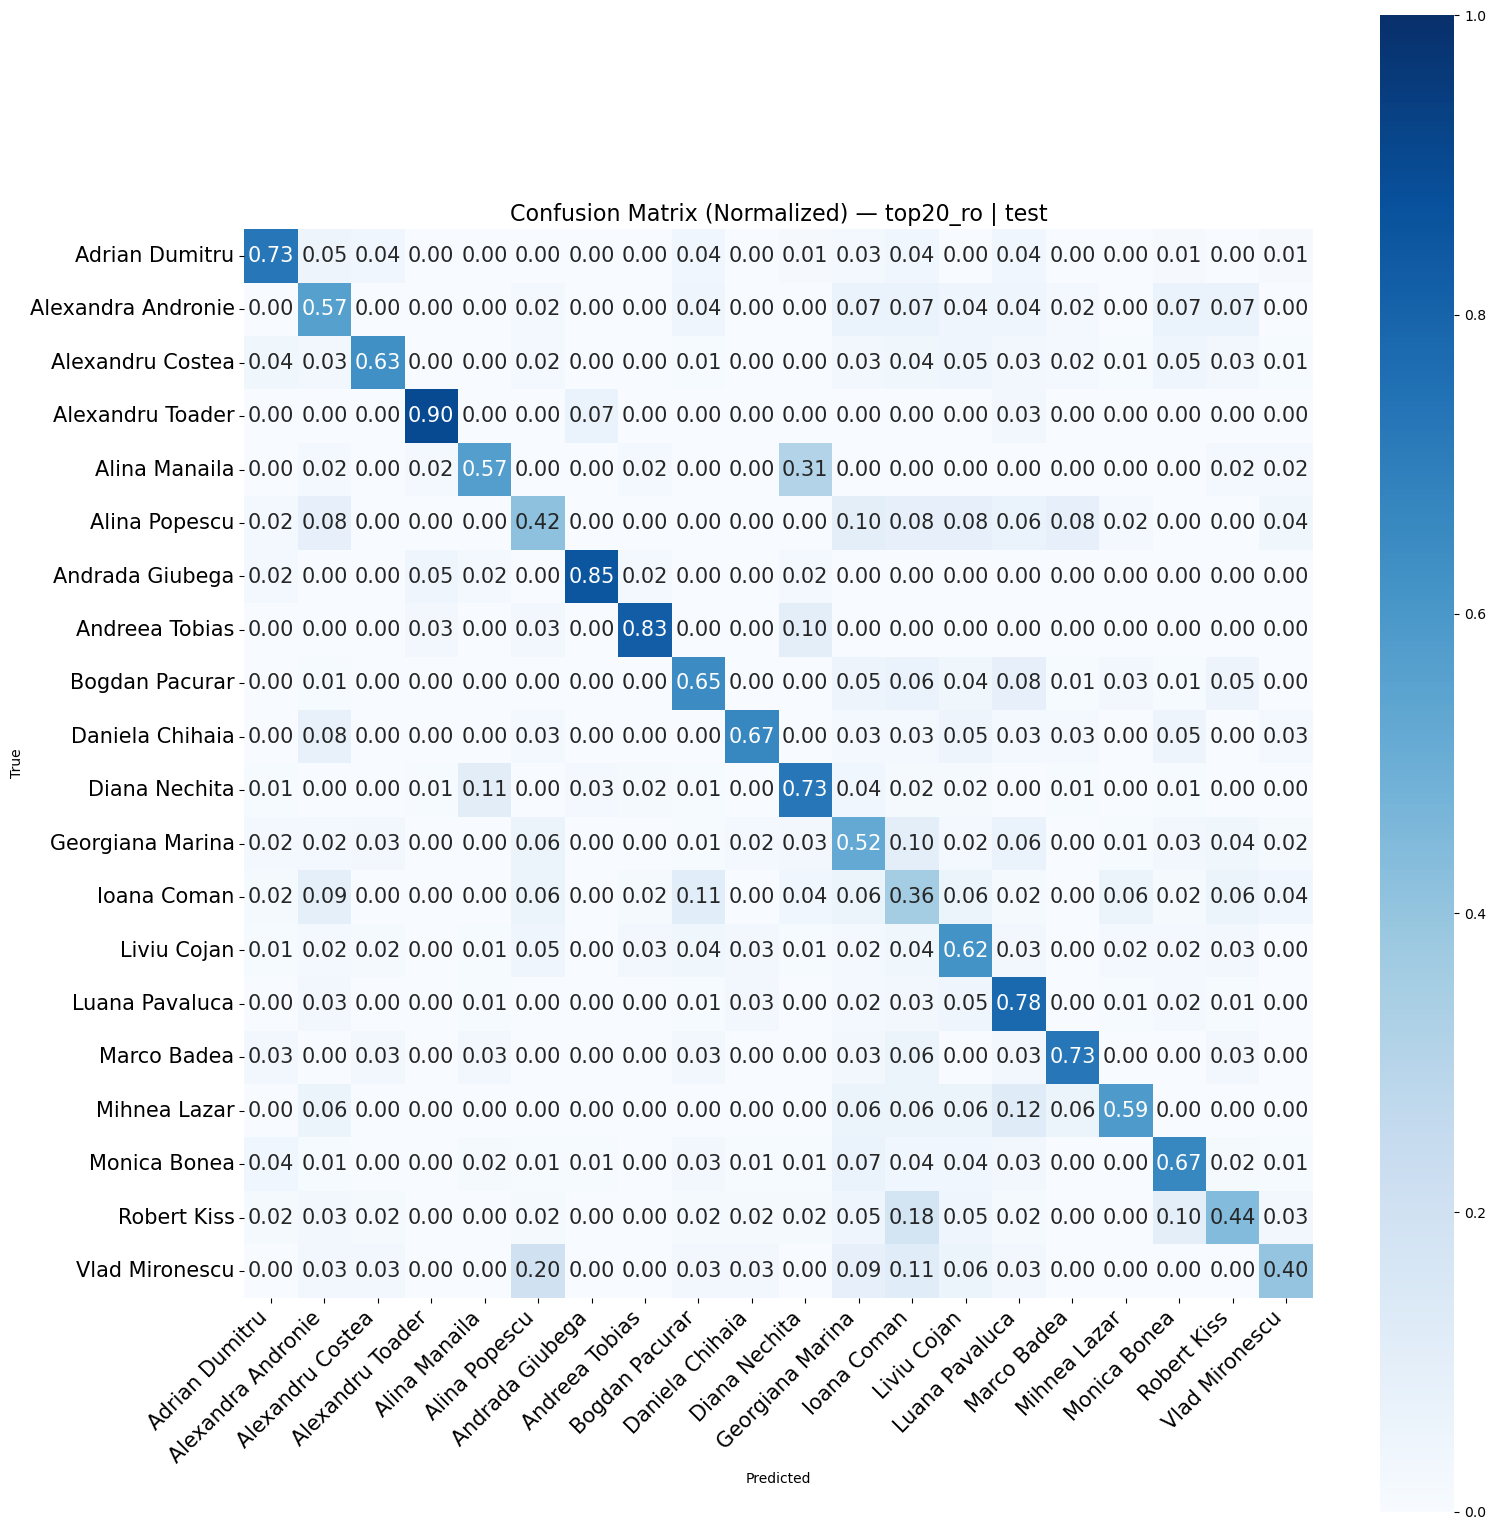

In [32]:
plot_confusion_matrix_bert(y_test_t20ro, preds_t20ro, label_encoder_t20ro, 'top20_ro', 'test', output_dir_1)

#### Top 40 Romania

In [16]:
top40_ro_train_text = pd.read_csv('final_stilo/top40_ro_train.csv')
top40_ro_val_text = pd.read_csv('final_stilo/top40_ro_val.csv')
top40_ro_test_text = pd.read_csv('final_stilo/top40_ro_test.csv')

In [17]:
train_loader_t40ro, val_loader_t40ro, test_loader_t40ro, le_t40ro, texts_test_t40ro, y_test_t40ro = build_dataloaders(
    top40_ro_train_text, top40_ro_val_text, top40_ro_test_text, tokenizer
)

Numar autori: 40
Autori: ['Adrian Dumitru' 'Alexandra Andronie' 'Alexandru Costea'
 'Alexandru Toader' 'Alina Manaila' 'Alina Popescu' 'Ana Petrescu'
 'Anca Dumitrescu' 'Andrada Giubega' 'Andreea Neblea' 'Andreea Tobias'
 'Bogdan Pacurar' 'Carmen Zanfir' 'Catalin Costache' 'Cosmin Pirv'
 'Cristian Anton' 'Cristian Matei' 'Dan Duca' 'Daniela Chihaia'
 'Diana Nechita' 'Dorin Oancea' 'Georgel Costita' 'Georgiana Marina'
 'Ioana Coman' 'Laura Buciu' 'Leila Bolat' 'Liviu Cojan' 'Luana Pavaluca'
 'Luminita Turcu' 'Marco Badea' 'Mihai Draghici' 'Mihnea Lazar'
 'Monica Bonea' 'Otilia Serescu' 'Petru Mazilu' 'Raul Netoiu'
 'Robert Kiss' 'Tatiana Beliuta' 'Valentina Postelnicu' 'Vlad Mironescu']

[DEBUG] Combining chars BEFORE clean:
Train combining: 1
Val   combining: 2
Test  combining: 2

[DEBUG] UNK check:
Train UNK: 10
Val   UNK: 40
Test  UNK: 0

[DEBUG] Combining chars AFTER clean:
Train combining: 0
Val   combining: 0
Test  combining: 0


train

In [18]:
output_dir_2 = f'{OUTPUT_DIR}/top40_ro'
os.makedirs(output_dir_2, exist_ok=True)

In [19]:
model_t40ro, model_path_t40ro, history_t40ro = run_transformer_experiment(
    train_loader_t40ro, val_loader_t40ro,
    num_labels=len(le_t40ro.classes_),
    device=device,
    dataset_name='top40_ro',
    epochs=6,
    output_dir=output_dir_2
)

# Epoch 1/6
#   Batch 0/8374 loss: 3.4965
#   Batch 100/8374 loss: 3.6440
#   Batch 200/8374 loss: 3.3836
#   Batch 300/8374 loss: 3.4249
#   Batch 400/8374 loss: 3.1595
#   Batch 500/8374 loss: 3.7606
#   Batch 600/8374 loss: 3.0535
#   Batch 700/8374 loss: 3.7376
#   Batch 800/8374 loss: 2.7633
# 502 minute

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Epoch 1/6
  Batch 0/8374 loss: 3.4965
  Batch 100/8374 loss: 3.6440
  Batch 200/8374 loss: 3.3836
  Batch 300/8374 loss: 3.4249
  Batch 400/8374 loss: 3.1595
  Batch 500/8374 loss: 3.7606
  Batch 600/8374 loss: 3.0535
  Batch 700/8374 loss: 3.7376
  Batch 800/8374 loss: 2.8078
  Batch 900/8374 loss: 3.5527
  Batch 1000/8374 loss: 3.1098
  Batch 1100/8374 loss: 2.6998
  Batch 1200/8374 loss: 2.7338
  Batch 1300/8374 loss: 2.9299
  Batch 1400/8374 loss: 2.2611
  Batch 1500/8374 loss: 2.5664
  Batch 1600/8374 loss: 2.4142
  Batch 1700/8374 loss: 2.2867
  Batch 1800/8374 loss: 3.1074
  Batch 1900/8374 loss: 1.7988
  Batch 2000/8374 loss: 1.8876
  Batch 2100/8374 loss: 1.9050
  Batch 2200/8374 loss: 2.3181
  Batch 2300/8374 loss: 2.0952
  Batch 2400/8374 loss: 2.7438
  Batch 2500/8374 loss: 2.0761
  Batch 2600/8374 loss: 2.3728
  Batch 2700/8374 loss: 2.3126
  Batch 2800/8374 loss: 2.8504
  Batch 2900/8374 loss: 2.2535
  Batch 3000/8374 loss: 1.7922
  Batch 3100/8374 loss: 1.4537
  Batch 3

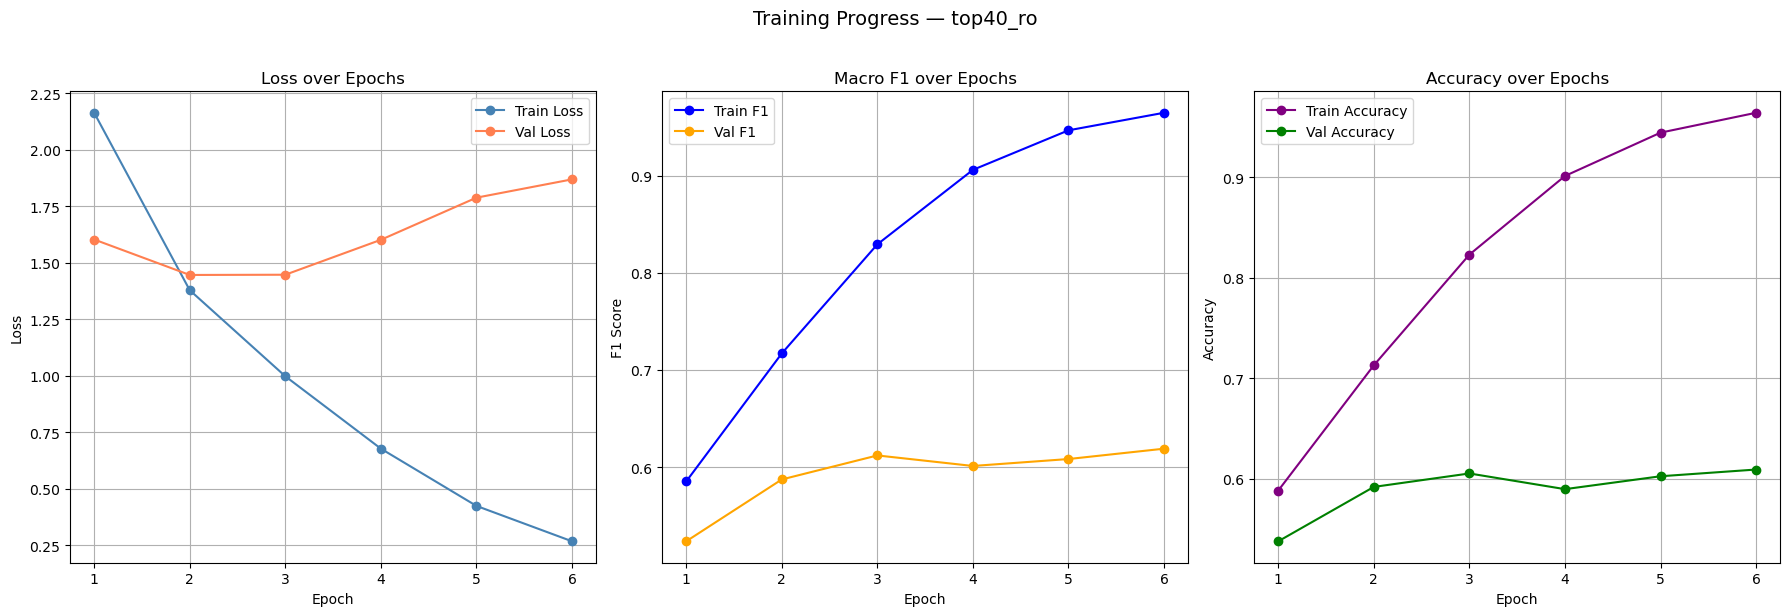

In [20]:
plot_training_curves(
    history_t40ro['train_losses'], history_t40ro['val_losses'],
    history_t40ro['train_f1s'],   history_t40ro['val_f1s'],
    history_t40ro['train_accs'],  history_t40ro['val_accs'],
    dataset_name='top40_ro', output_dir=output_dir_2
)

In [21]:
current_model_path_40ro = 'outputs_transformer_baseline/top40_ro/best_model_top40_ro.pt'

In [22]:
preds_t40ro, f1_t40ro, acc_t40ro = evaluate_with_voting(
    texts_test_t40ro, y_test_t40ro,
    tokenizer, le_t40ro, device, 
    dataset_name='top40_ro',
    model_path=current_model_path_40ro
)


Evaluare cu majority voting pe test — top40_ro


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Incarcat best model din outputs_transformer_baseline/top40_ro/best_model_top40_ro.pt

Test F1 macro: 0.6016 | Accuracy: 0.6065
                      precision    recall  f1-score   support

      Adrian Dumitru       0.72      0.73      0.72        77
  Alexandra Andronie       0.43      0.52      0.47        46
    Alexandru Costea       0.80      0.59      0.68       100
    Alexandru Toader       0.56      0.60      0.58        30
       Alina Manaila       0.66      0.69      0.67        42
       Alina Popescu       0.49      0.48      0.48        48
        Ana Petrescu       0.95      0.91      0.93        22
     Anca Dumitrescu       0.92      0.65      0.76        17
     Andrada Giubega       0.79      0.80      0.80        41
      Andreea Neblea       0.68      0.55      0.61        31
      Andreea Tobias       0.58      0.66      0.61        29
      Bogdan Pacurar       0.66      0.64      0.65        96
       Carmen Zanfir       0.76      0.79      0.78        33
    

In [23]:
results = []

In [24]:
results.append({
    'Experiment': 'BERT Baseline',
    'dataset': 'top40_ro',
    'test_f1': round(f1_t40ro, 4),
    'test_acc': round(acc_t40ro, 4),
    'best val f1': round(history_t40ro['best_val_f1'], 4)  # best val f1
})

In [25]:
display(pd.DataFrame(results))

,Experiment,dataset,test_f1,test_acc,best val f1
0,BERT Baseline,top40_ro,0.6016,0.6065,0.6189


In [26]:
# dump la results
output_file_40ro = f'{output_dir_2}/results.json'
with open(output_file_40ro, 'w') as f:
    json.dump(results, f, indent=2)

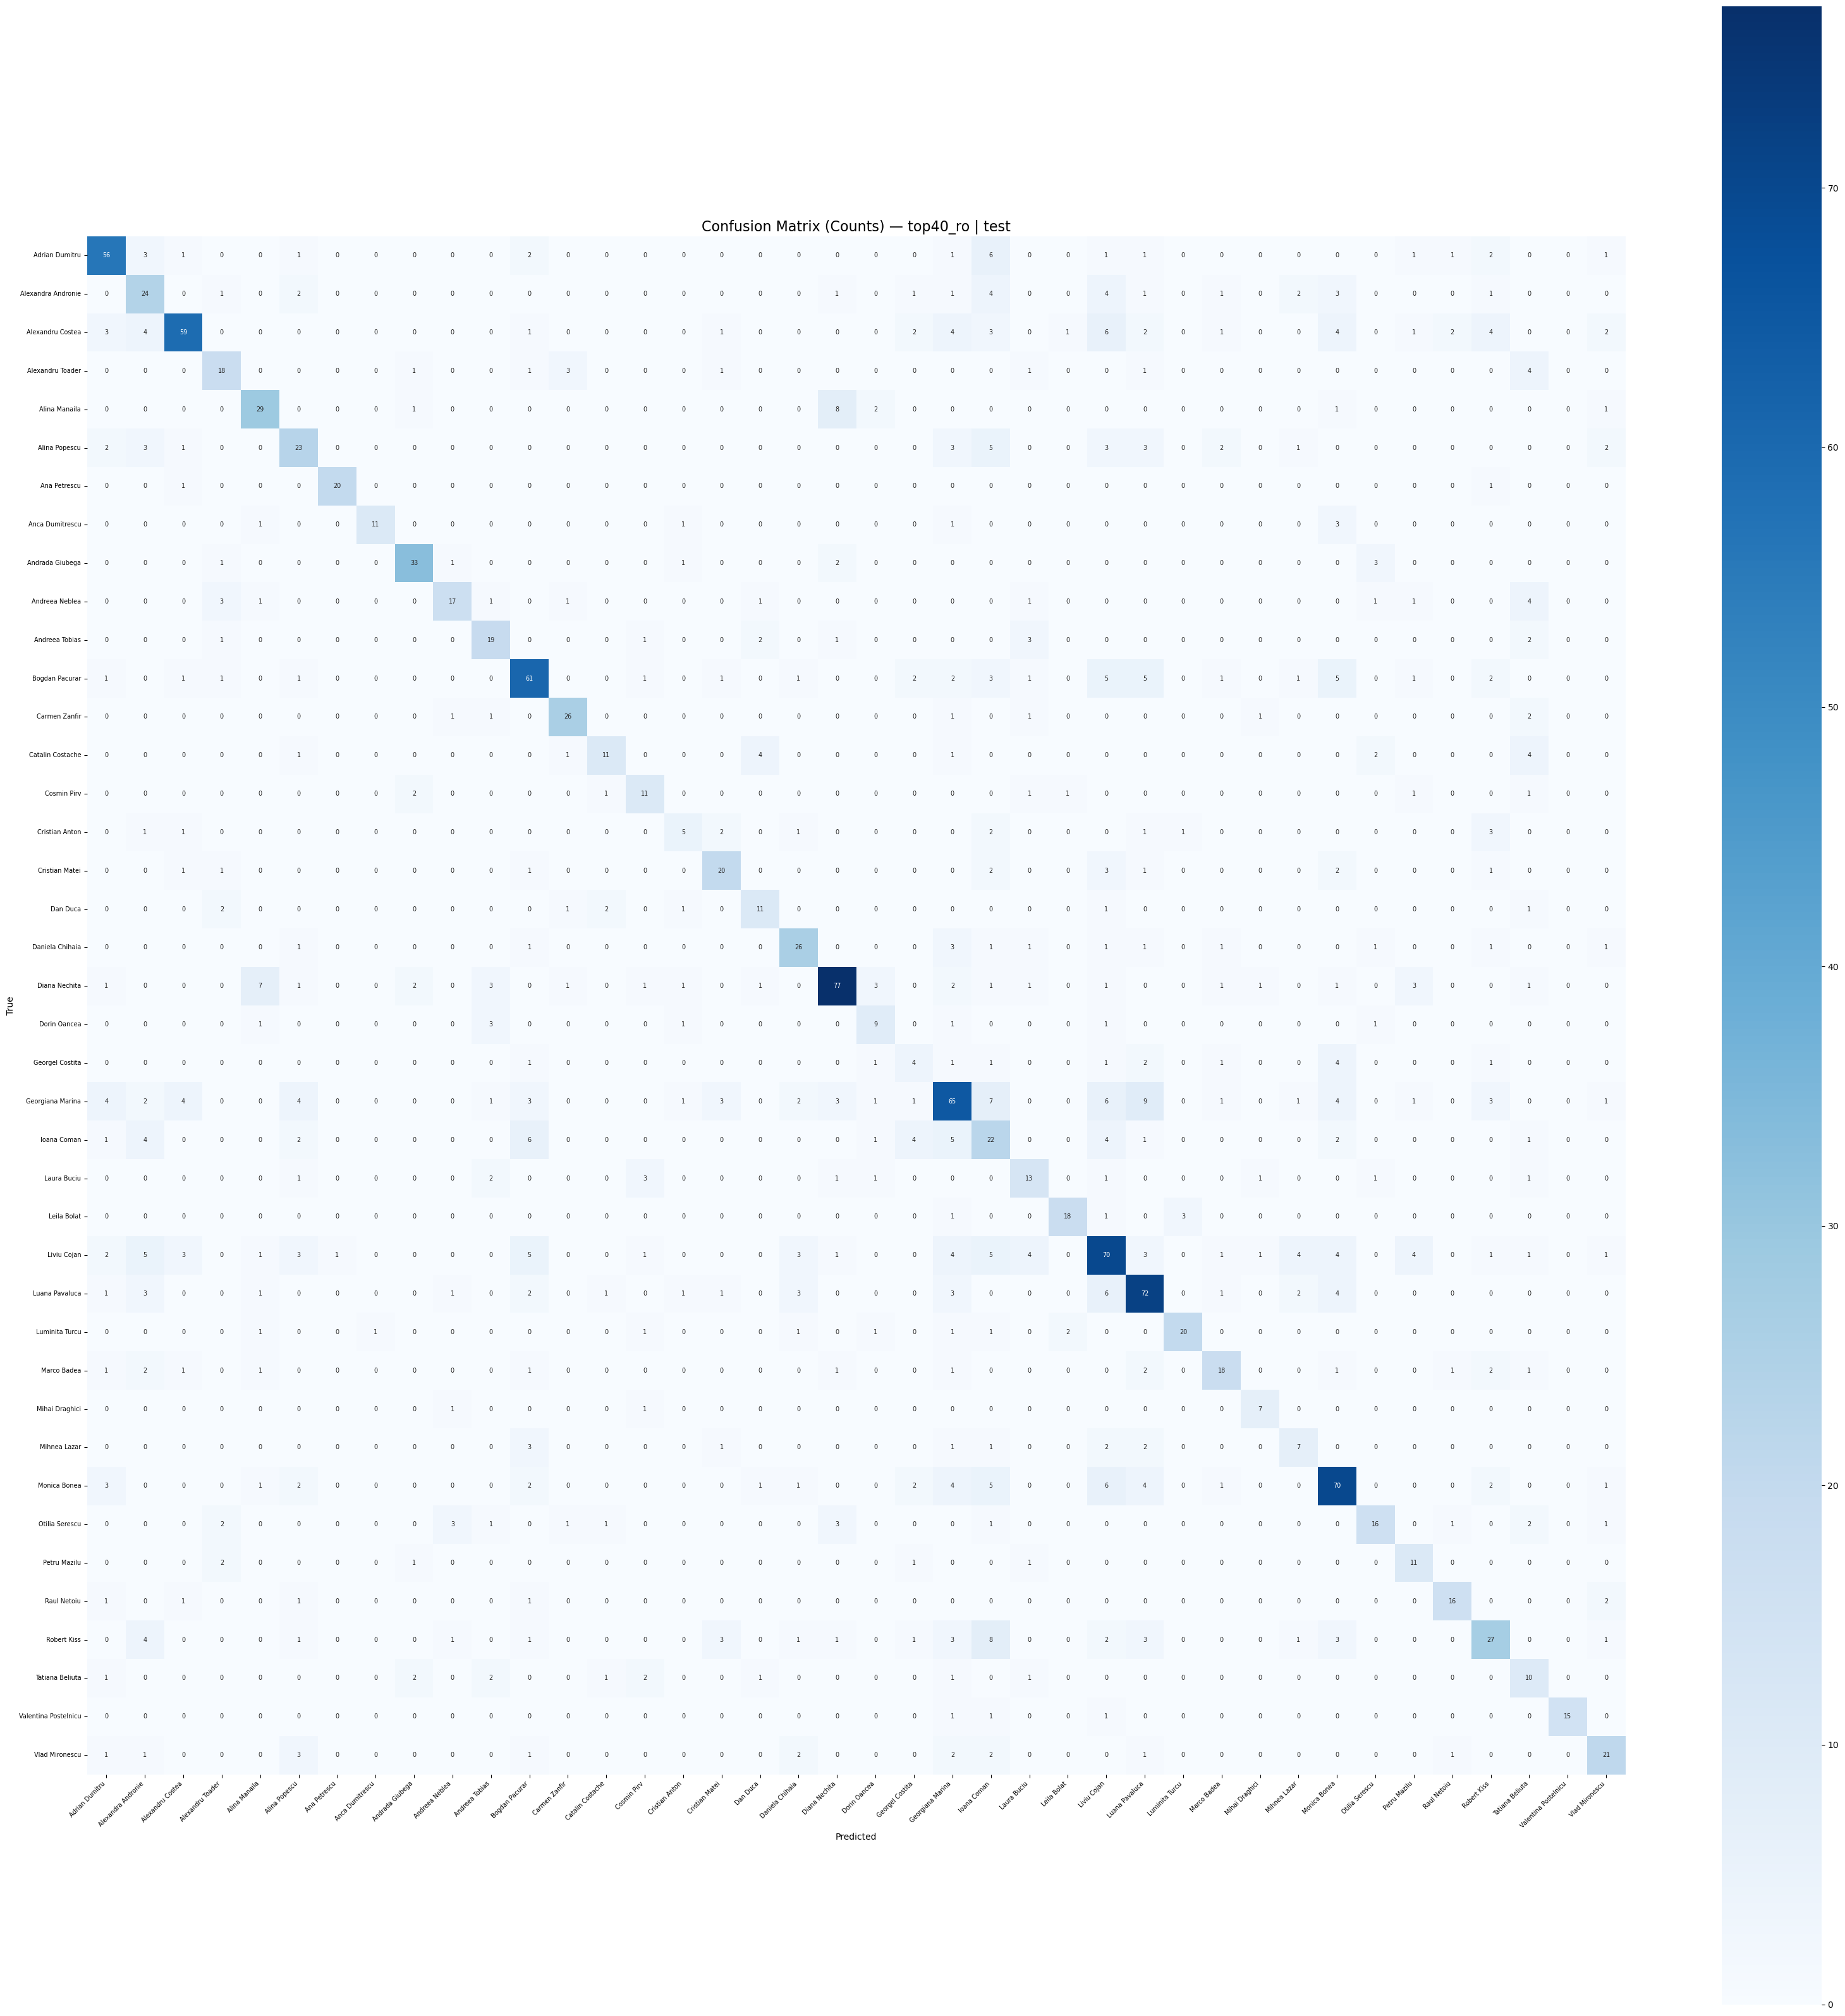

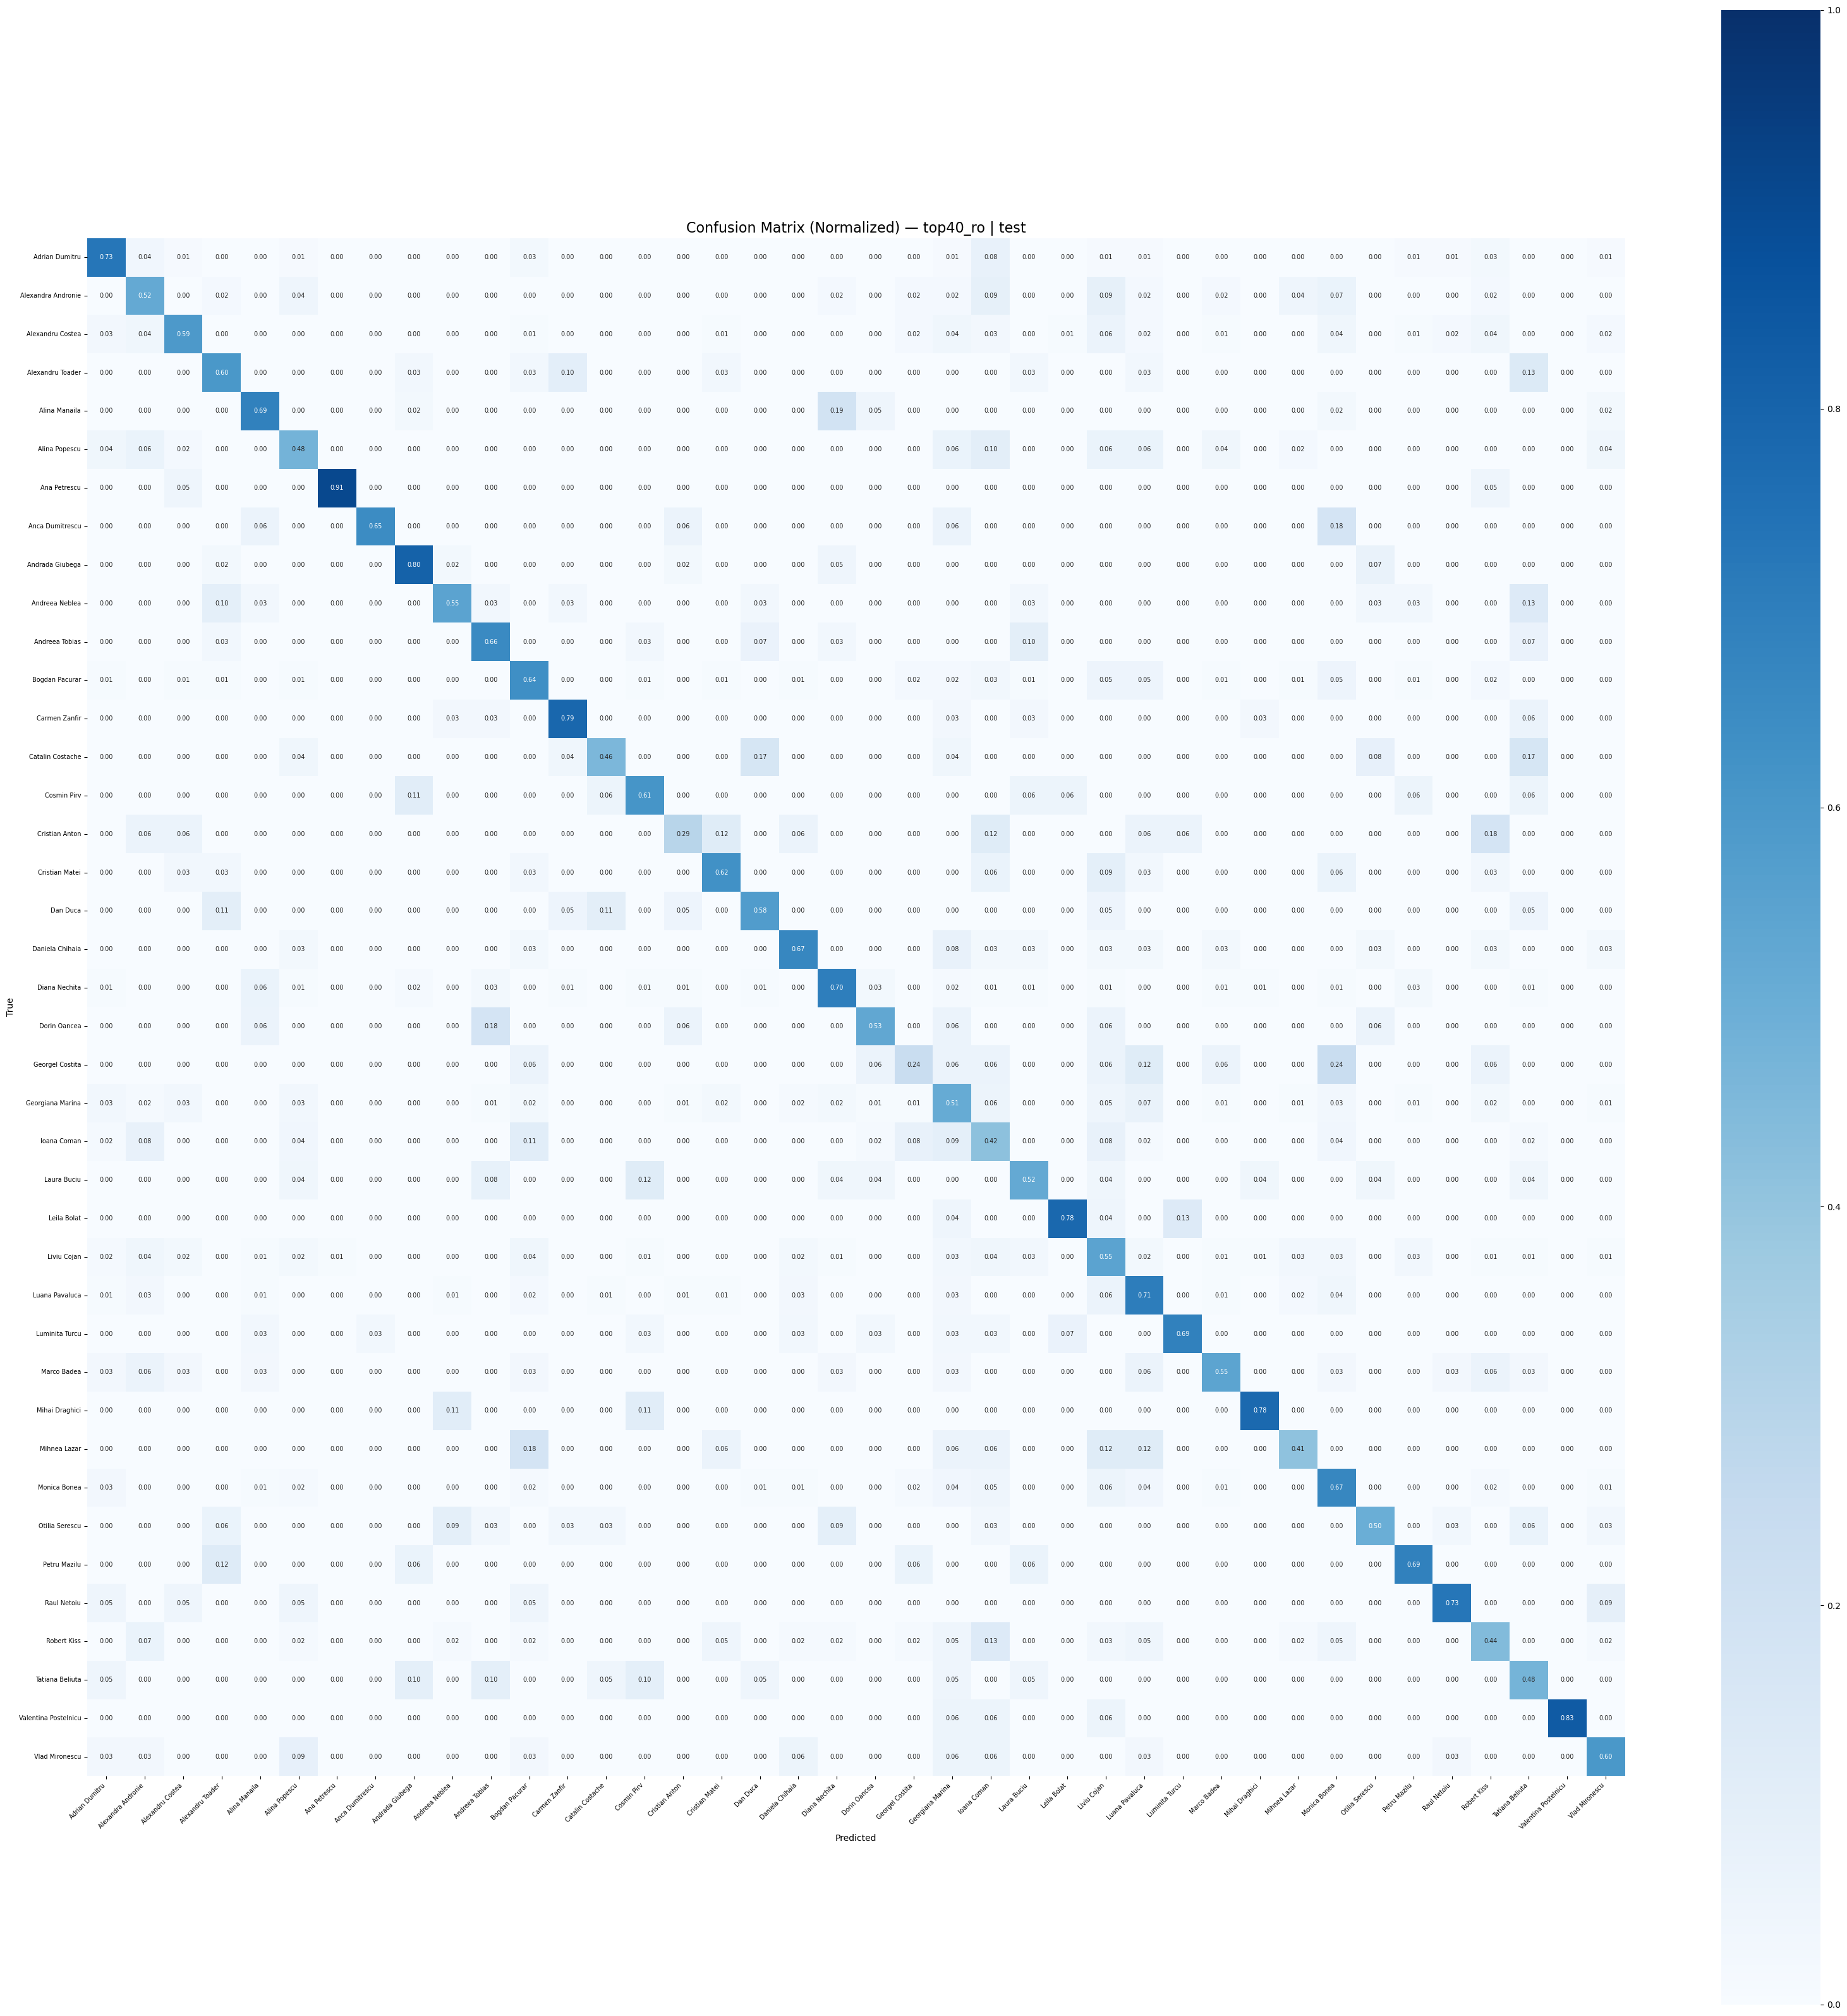

In [27]:
plot_confusion_matrix_bert(y_test_t40ro, preds_t40ro, le_t40ro, 'top40_ro', 'test', output_dir_2)

### Moldova

In [27]:
# citim top 20
top20_mo_train_text = pd.read_csv('final_stilo/top20_mo_train.csv')
top20_mo_val_text = pd.read_csv('final_stilo/top20_mo_val.csv')
top20_mo_test_text = pd.read_csv('final_stilo/top20_mo_test.csv')

In [28]:
train_loader_t20mo, val_loader_t20mo, test_loader_t20mo, le_t20mo, texts_test_t20mo, y_test_t20mo = build_dataloaders(
    top20_mo_train_text, top20_mo_val_text, top20_mo_test_text, tokenizer
)

Numar autori: 20
Autori: ['Aliona Ciurca' 'Ana-Maria Dolghii' 'Cristian Sava' 'Cristina Dulea'
 'Cristina Mirca' 'Cristina Popescu' 'Diana Gatcan' 'Diana Severin'
 'Ecaterina Arvintii' 'Malvina Cojocari' 'Marina Ciobanu' 'Maxim Stratan'
 'Mihaela Conovali' 'Milena Onisim' 'Nicoleta Braghis' 'Stela Untila'
 'Svetlana Cartin' 'Svetlana Cojocaru' 'Valentina Buza' 'Viorica Rusu']

[DEBUG] Combining chars BEFORE clean:
Train combining: 343
Val   combining: 422
Test  combining: 366

[DEBUG] UNK check:
Train UNK: 43
Val   UNK: 33
Test  UNK: 53

[DEBUG] Combining chars AFTER clean:
Train combining: 0
Val   combining: 0
Test  combining: 0


In [29]:
output_dir_3 = f'{OUTPUT_DIR}/top20_mo'
os.makedirs(output_dir_3, exist_ok=True)

In [30]:
model_t20mo, model_path_t20mo, history_t20mo = run_transformer_experiment(
    train_loader_t20mo, val_loader_t20mo,
    num_labels=len(le_t20mo.classes_),
    device=device,
    dataset_name='top20_mo',
    epochs=6,
    output_dir=output_dir_3
)
# 160 minute 3 epoci
# am schimbat la 6 
# Epoch 1/6
#   Batch 0/4917 loss: 3.2171
#   Batch 100/4917 loss: 3.1129
#   Batch 200/4917 loss: 2.8868
#   Batch 300/4917 loss: 2.8027
#   Batch 400/4917 loss: 2.7060
#   Batch 500/4917 loss: 2.0845
# 330 minute

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Epoch 1/6
  Batch 0/4917 loss: 3.2171
  Batch 100/4917 loss: 3.1129
  Batch 200/4917 loss: 2.8868
  Batch 300/4917 loss: 2.8027
  Batch 400/4917 loss: 2.4919
  Batch 500/4917 loss: 2.1789
  Batch 600/4917 loss: 2.4044
  Batch 700/4917 loss: 1.8037
  Batch 800/4917 loss: 1.5582
  Batch 900/4917 loss: 1.4839
  Batch 1000/4917 loss: 1.5984
  Batch 1100/4917 loss: 1.9803
  Batch 1200/4917 loss: 1.7346
  Batch 1300/4917 loss: 1.7951
  Batch 1400/4917 loss: 1.9129
  Batch 1500/4917 loss: 1.3994
  Batch 1600/4917 loss: 2.0461
  Batch 1700/4917 loss: 1.5349
  Batch 1800/4917 loss: 1.3568
  Batch 1900/4917 loss: 1.3515
  Batch 2000/4917 loss: 1.6715
  Batch 2100/4917 loss: 1.7159
  Batch 2200/4917 loss: 1.2610
  Batch 2300/4917 loss: 1.1321
  Batch 2400/4917 loss: 2.4469
  Batch 2500/4917 loss: 1.4111
  Batch 2600/4917 loss: 1.4494
  Batch 2700/4917 loss: 1.6637
  Batch 2800/4917 loss: 1.0991
  Batch 2900/4917 loss: 0.8559
  Batch 3000/4917 loss: 1.2568
  Batch 3100/4917 loss: 1.1731
  Batch 3

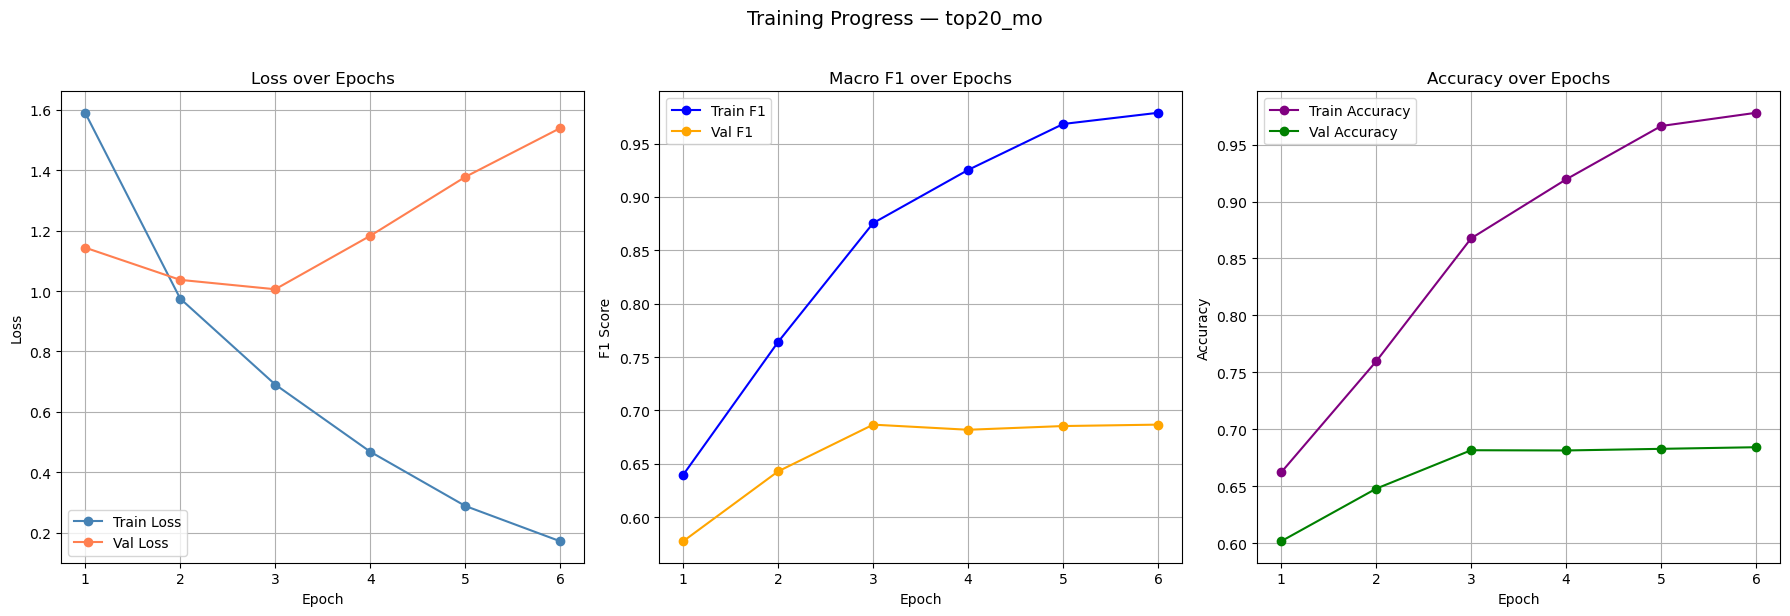

In [31]:
plot_training_curves(
    history_t20mo['train_losses'], history_t20mo['val_losses'],
    history_t20mo['train_f1s'],   history_t20mo['val_f1s'],
    history_t20mo['train_accs'],  history_t20mo['val_accs'],
    dataset_name='top20_mo', output_dir=output_dir_3
)

In [32]:
current_model_path_mo20 = 'outputs_transformer_baseline/top20_mo/best_model_top20_mo.pt'

In [33]:
preds_t20mo, f1_t20mo, acc_t20mo = evaluate_with_voting(
    texts_test_t20mo, y_test_t20mo,
    tokenizer, le_t20mo, device, 
    dataset_name='top20_mo',
    model_path=current_model_path_mo20
)


Evaluare cu majority voting pe test — top20_mo


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Incarcat best model din outputs_transformer_baseline/top20_mo/best_model_top20_mo.pt

Test F1 macro: 0.6773 | Accuracy: 0.6783
                    precision    recall  f1-score   support

     Aliona Ciurca       0.78      0.71      0.74       150
 Ana-Maria Dolghii       0.48      0.56      0.52       121
     Cristian Sava       0.46      0.45      0.46       328
    Cristina Dulea       0.75      0.69      0.72       119
    Cristina Mirca       0.56      0.57      0.57       271
  Cristina Popescu       0.36      0.37      0.36       289
      Diana Gatcan       0.68      0.84      0.75       269
     Diana Severin       0.82      0.76      0.79       284
Ecaterina Arvintii       0.67      0.77      0.72       164
  Malvina Cojocari       0.46      0.42      0.44       131
    Marina Ciobanu       0.83      0.75      0.79       175
     Maxim Stratan       0.81      0.90      0.85       230
  Mihaela Conovali       0.86      0.82      0.84       379
     Milena Onisim       0.88   

In [34]:
results = []

In [35]:
results.append({
    'Experiment': 'BERT Baseline',
    'dataset': 'top20_mo',
    'test_f1': round(f1_t20mo, 4),
    'test_acc': round(acc_t20mo, 4),
    'best val f1': round(history_t20mo['best_val_f1'], 4)  # best val f1
})

In [36]:
display(pd.DataFrame(results))

,Experiment,dataset,test_f1,test_acc,best val f1
0,BERT Baseline,top20_mo,0.6773,0.6783,0.6866


In [ ]:
# dump
output_file_20mo = f'{output_dir_3}/results.json'
with open(output_file_20mo, 'w') as f:
    json.dump(results, f, indent=2)


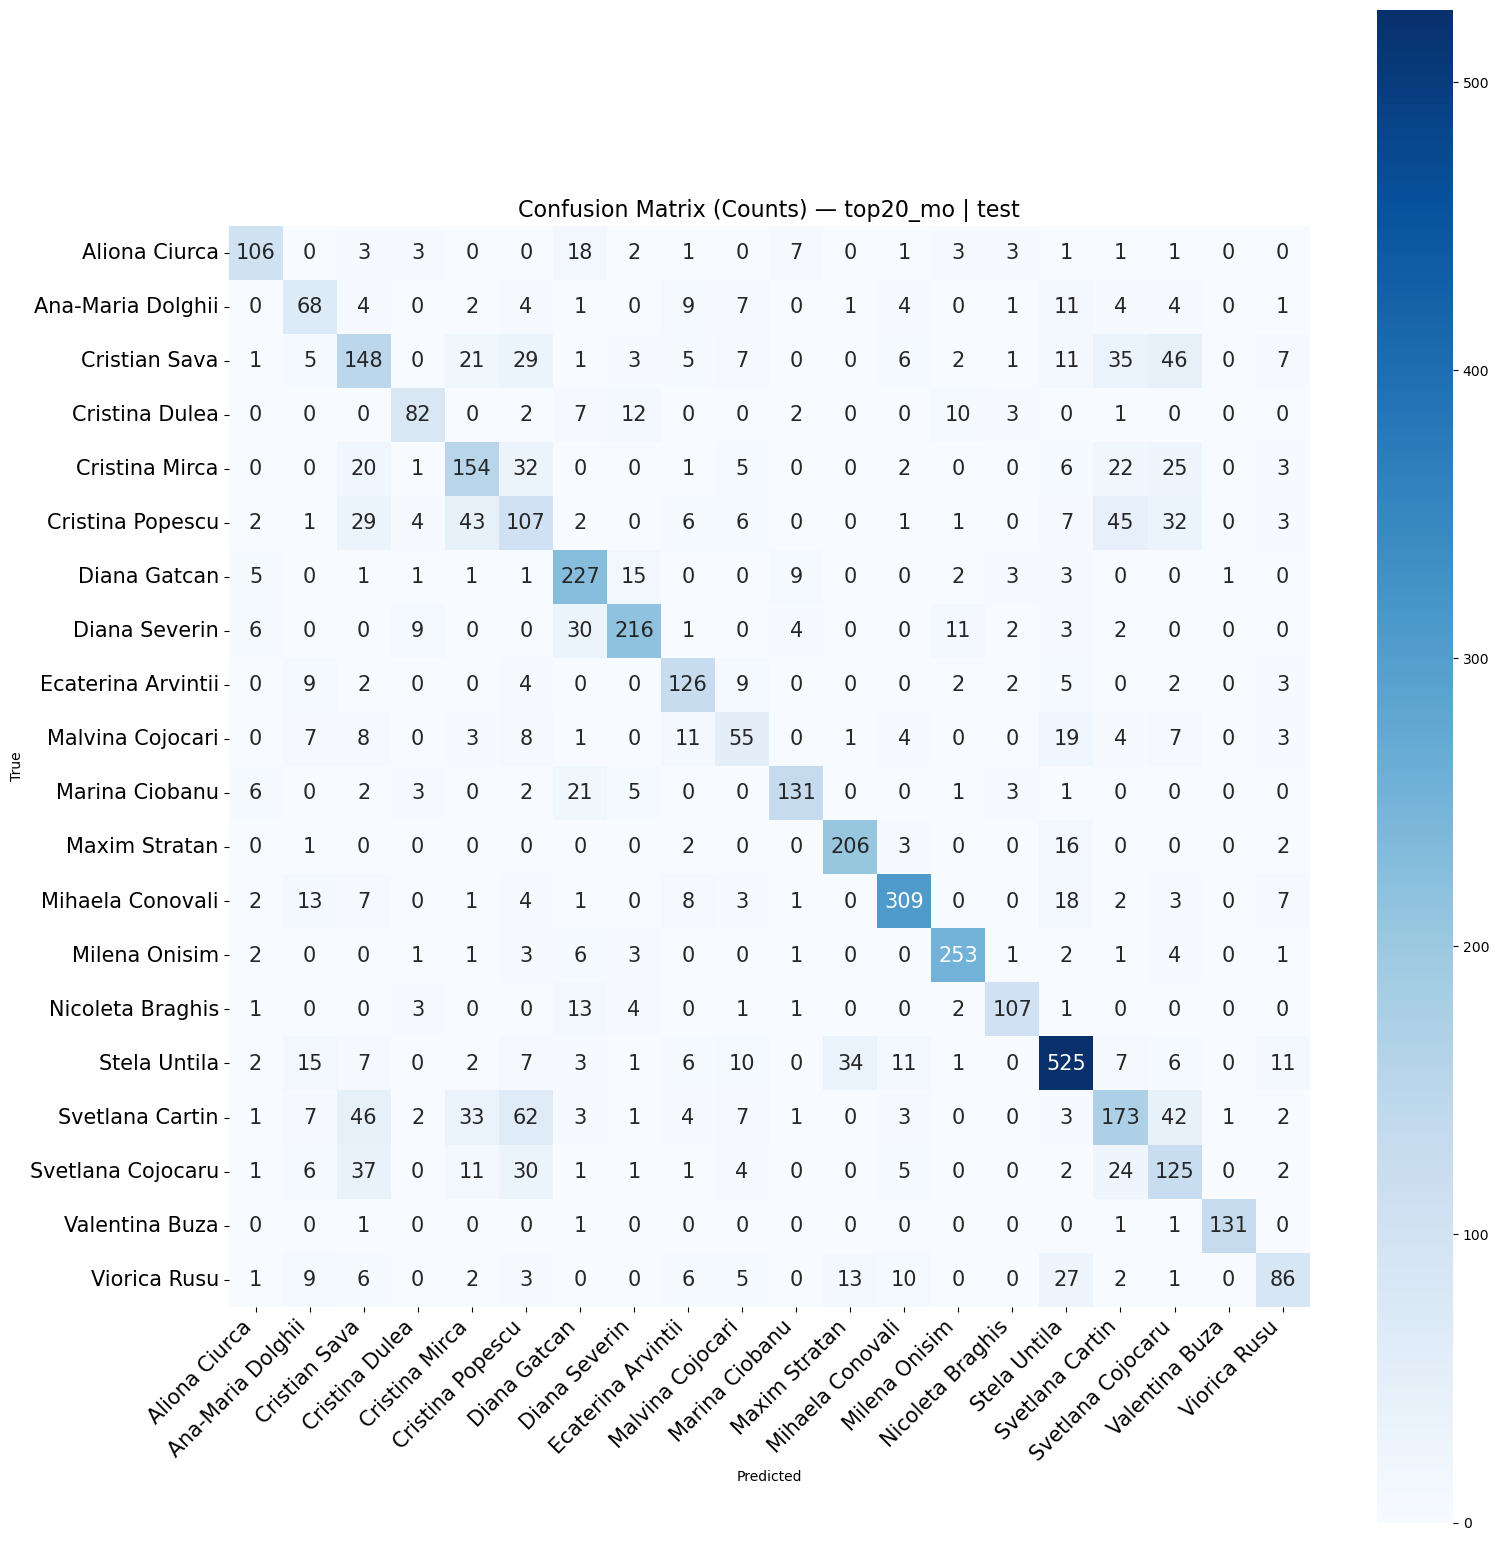

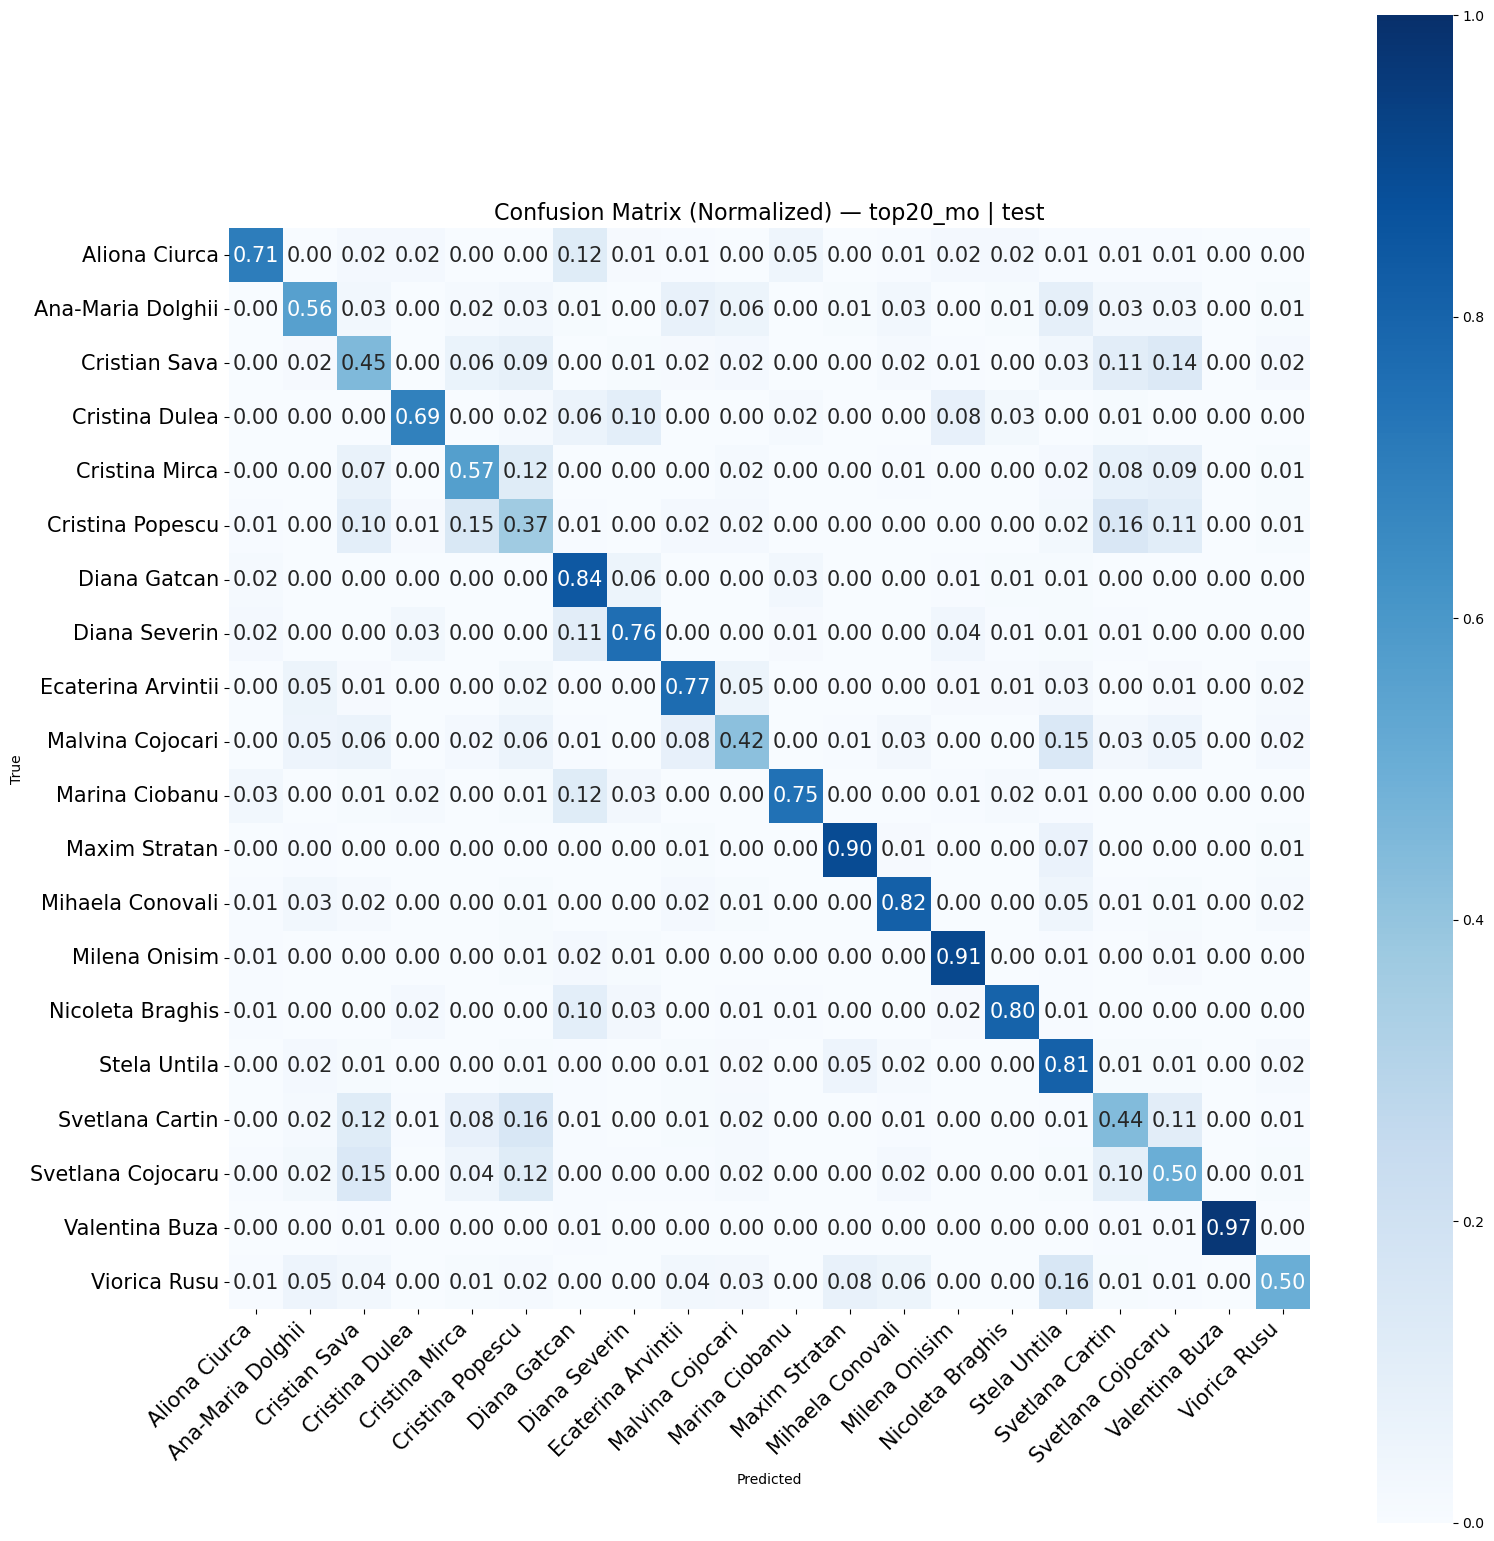

In [37]:
plot_confusion_matrix_bert(y_test_t20mo, preds_t20mo, le_t20mo, 'top20_mo', 'test', output_dir_3)

Top 40

In [16]:
top40_mo_train_text = pd.read_csv('final_stilo/top40_mo_train.csv')
top40_mo_val_text = pd.read_csv('final_stilo/top40_mo_val.csv')
top40_mo_test_text = pd.read_csv('final_stilo/top40_mo_test.csv')

In [17]:
# loadere
train_loader_t40mo, val_loader_t40mo, test_loader_t40mo, le_t40mo, texts_test_t40mo, y_test_t40mo = build_dataloaders(
    top40_mo_train_text, top40_mo_val_text, top40_mo_test_text, tokenizer
)

Numar autori: 40
Autori: ['Alina Radu' 'Aliona Ciurca' 'Ana-Maria Dolghii' 'Anatolie Esanu'
 'Aneta Grosu' 'Buzdugan Loredana' 'Constantin Uzdris' 'Cristian Sava'
 'Cristina Dulea' 'Cristina Mirca' 'Cristina Popescu' 'Diana Gatcan'
 'Diana Severin' 'Dorina Butnaras' 'Ecaterina Arvintii' 'Elena Cornea'
 'Elena Mudrii' 'Elena Putregai' 'Frunza Alina' 'Malvina Cojocari'
 'Maria Palade' 'Maria Svet' 'Marina Ciobanu' 'Maxim Stratan'
 'Mihaela Conovali' 'Milena Onisim' 'Nicoleta Braghis' 'Stela Untila'
 'Svetlana Cartin' 'Svetlana Cojocaru' 'Tatiana Beghiu' 'Tatiana Rusnac'
 'Ursu Ana' 'Vadim Sterbate' 'Valentina Buza' 'Victor Cobasneanu'
 'Victor Mosneag' 'Victoria Borodin' 'Victoria Laur' 'Viorica Rusu']

[DEBUG] Combining chars BEFORE clean:
Train combining: 327
Val   combining: 351
Test  combining: 333

[DEBUG] UNK check:
Train UNK: 21
Val   UNK: 77
Test  UNK: 27

[DEBUG] Combining chars AFTER clean:
Train combining: 0
Val   combining: 0
Test  combining: 0


In [18]:
output_dir_4 = f'{OUTPUT_DIR}/top40_mo'
os.makedirs(output_dir_4, exist_ok=True)

In [ ]:
model_t40mo, model_path_t40mo, history_t40mo = run_transformer_experiment(
    train_loader_t40mo, val_loader_t40mo,
    num_labels=len(le_t40mo.classes_),
    device=device,
    dataset_name='top40_mo',
    epochs=6,
    output_dir=output_dir_4
)
#388 minute
#  Batch 0/5902 loss: 3.9428
#   Batch 100/5902 loss: 3.6344
#   Batch 200/5902 loss: 3.3665
#   Batch 300/5902 loss: 3.3967
#   Batch 400/5902 loss: 2.0224
#   Batch 500/5902 loss: 2.4324
# 359 minute

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Epoch 1/6
  Batch 0/5902 loss: 3.9428
  Batch 100/5902 loss: 3.6344
  Batch 200/5902 loss: 3.3665
  Batch 300/5902 loss: 3.3036
  Batch 400/5902 loss: 2.0291
  Batch 500/5902 loss: 2.4742
  Batch 600/5902 loss: 2.7466
  Batch 700/5902 loss: 2.7764
  Batch 800/5902 loss: 3.0360
  Batch 900/5902 loss: 2.6856
  Batch 1000/5902 loss: 2.7129
  Batch 1100/5902 loss: 2.7993
  Batch 1200/5902 loss: 2.9213
  Batch 1300/5902 loss: 2.4424
  Batch 1400/5902 loss: 1.8693
  Batch 1500/5902 loss: 1.7533
  Batch 1600/5902 loss: 3.4930
  Batch 1700/5902 loss: 2.3374
  Batch 1800/5902 loss: 2.1823
  Batch 1900/5902 loss: 1.4734
  Batch 2000/5902 loss: 2.2040
  Batch 2100/5902 loss: 2.0118
  Batch 2200/5902 loss: 1.8475
  Batch 2300/5902 loss: 1.3287
  Batch 2400/5902 loss: 2.9030
  Batch 2500/5902 loss: 1.2956
  Batch 2600/5902 loss: 2.2526
  Batch 2700/5902 loss: 2.3806
  Batch 2800/5902 loss: 1.7918
  Batch 2900/5902 loss: 1.9175
  Batch 3000/5902 loss: 2.9890
  Batch 3100/5902 loss: 1.4038
  Batch 3

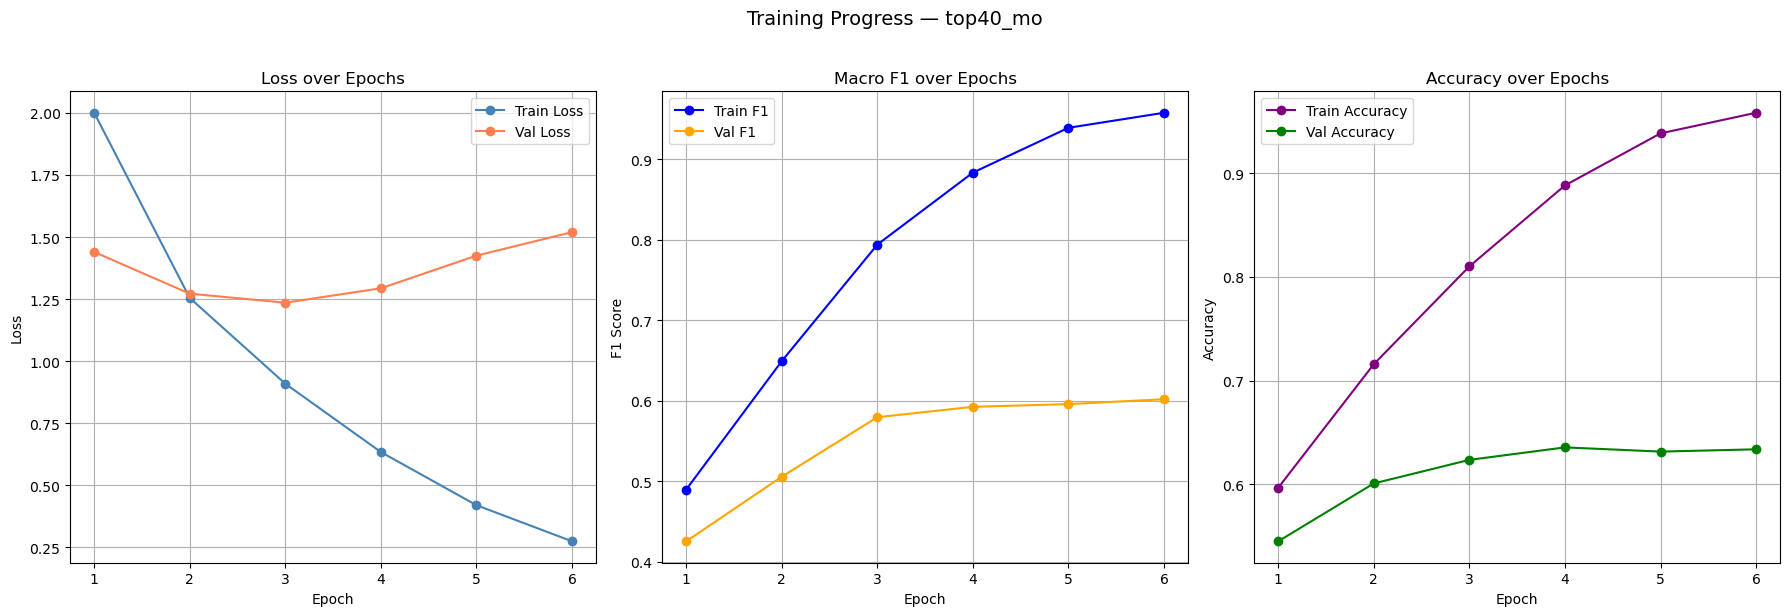

In [20]:
plot_training_curves(
    history_t40mo['train_losses'], history_t40mo['val_losses'],
    history_t40mo['train_f1s'],   history_t40mo['val_f1s'],
    history_t40mo['train_accs'],  history_t40mo['val_accs'],
    dataset_name='top40_mo', output_dir=output_dir_4
)

In [21]:
current_model_path_mo40 = 'outputs_transformer_baseline/top40_mo/best_model_top40_mo.pt'

In [ ]:
preds_t40mo, f1_t40mo, acc_t40mo = evaluate_with_voting(
    texts_test_t40mo, y_test_t40mo,
    tokenizer, le_t40mo, device,
    dataset_name='top40_mo',
    model_path=current_model_path_mo40
)
# 2 mins 46 s


Evaluare cu majority voting pe test — top40_mo


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dumitrescustefan/bert-base-romanian-cased-v1
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Incarcat best model din outputs_transformer_baseline/top40_mo/best_model_top40_mo.pt

Test F1 macro: 0.6019 | Accuracy: 0.6406
                    precision    recall  f1-score   support

        Alina Radu       0.50      0.09      0.15        11
     Aliona Ciurca       0.73      0.65      0.69       150
 Ana-Maria Dolghii       0.43      0.53      0.47       122
    Anatolie Esanu       0.64      0.35      0.45        20
       Aneta Grosu       0.49      0.48      0.48        48
 Buzdugan Loredana       0.62      0.42      0.50        38
 Constantin Uzdris       0.15      0.06      0.09        81
     Cristian Sava       0.49      0.46      0.48       327
    Cristina Dulea       0.71      0.67      0.69       120
    Cristina Mirca       0.55      0.56      0.55       271
  Cristina Popescu       0.36      0.38      0.37       289
      Diana Gatcan       0.70      0.85      0.77       268
     Diana Severin       0.73      0.74      0.73       284
   Dorina Butnaras       0.65   

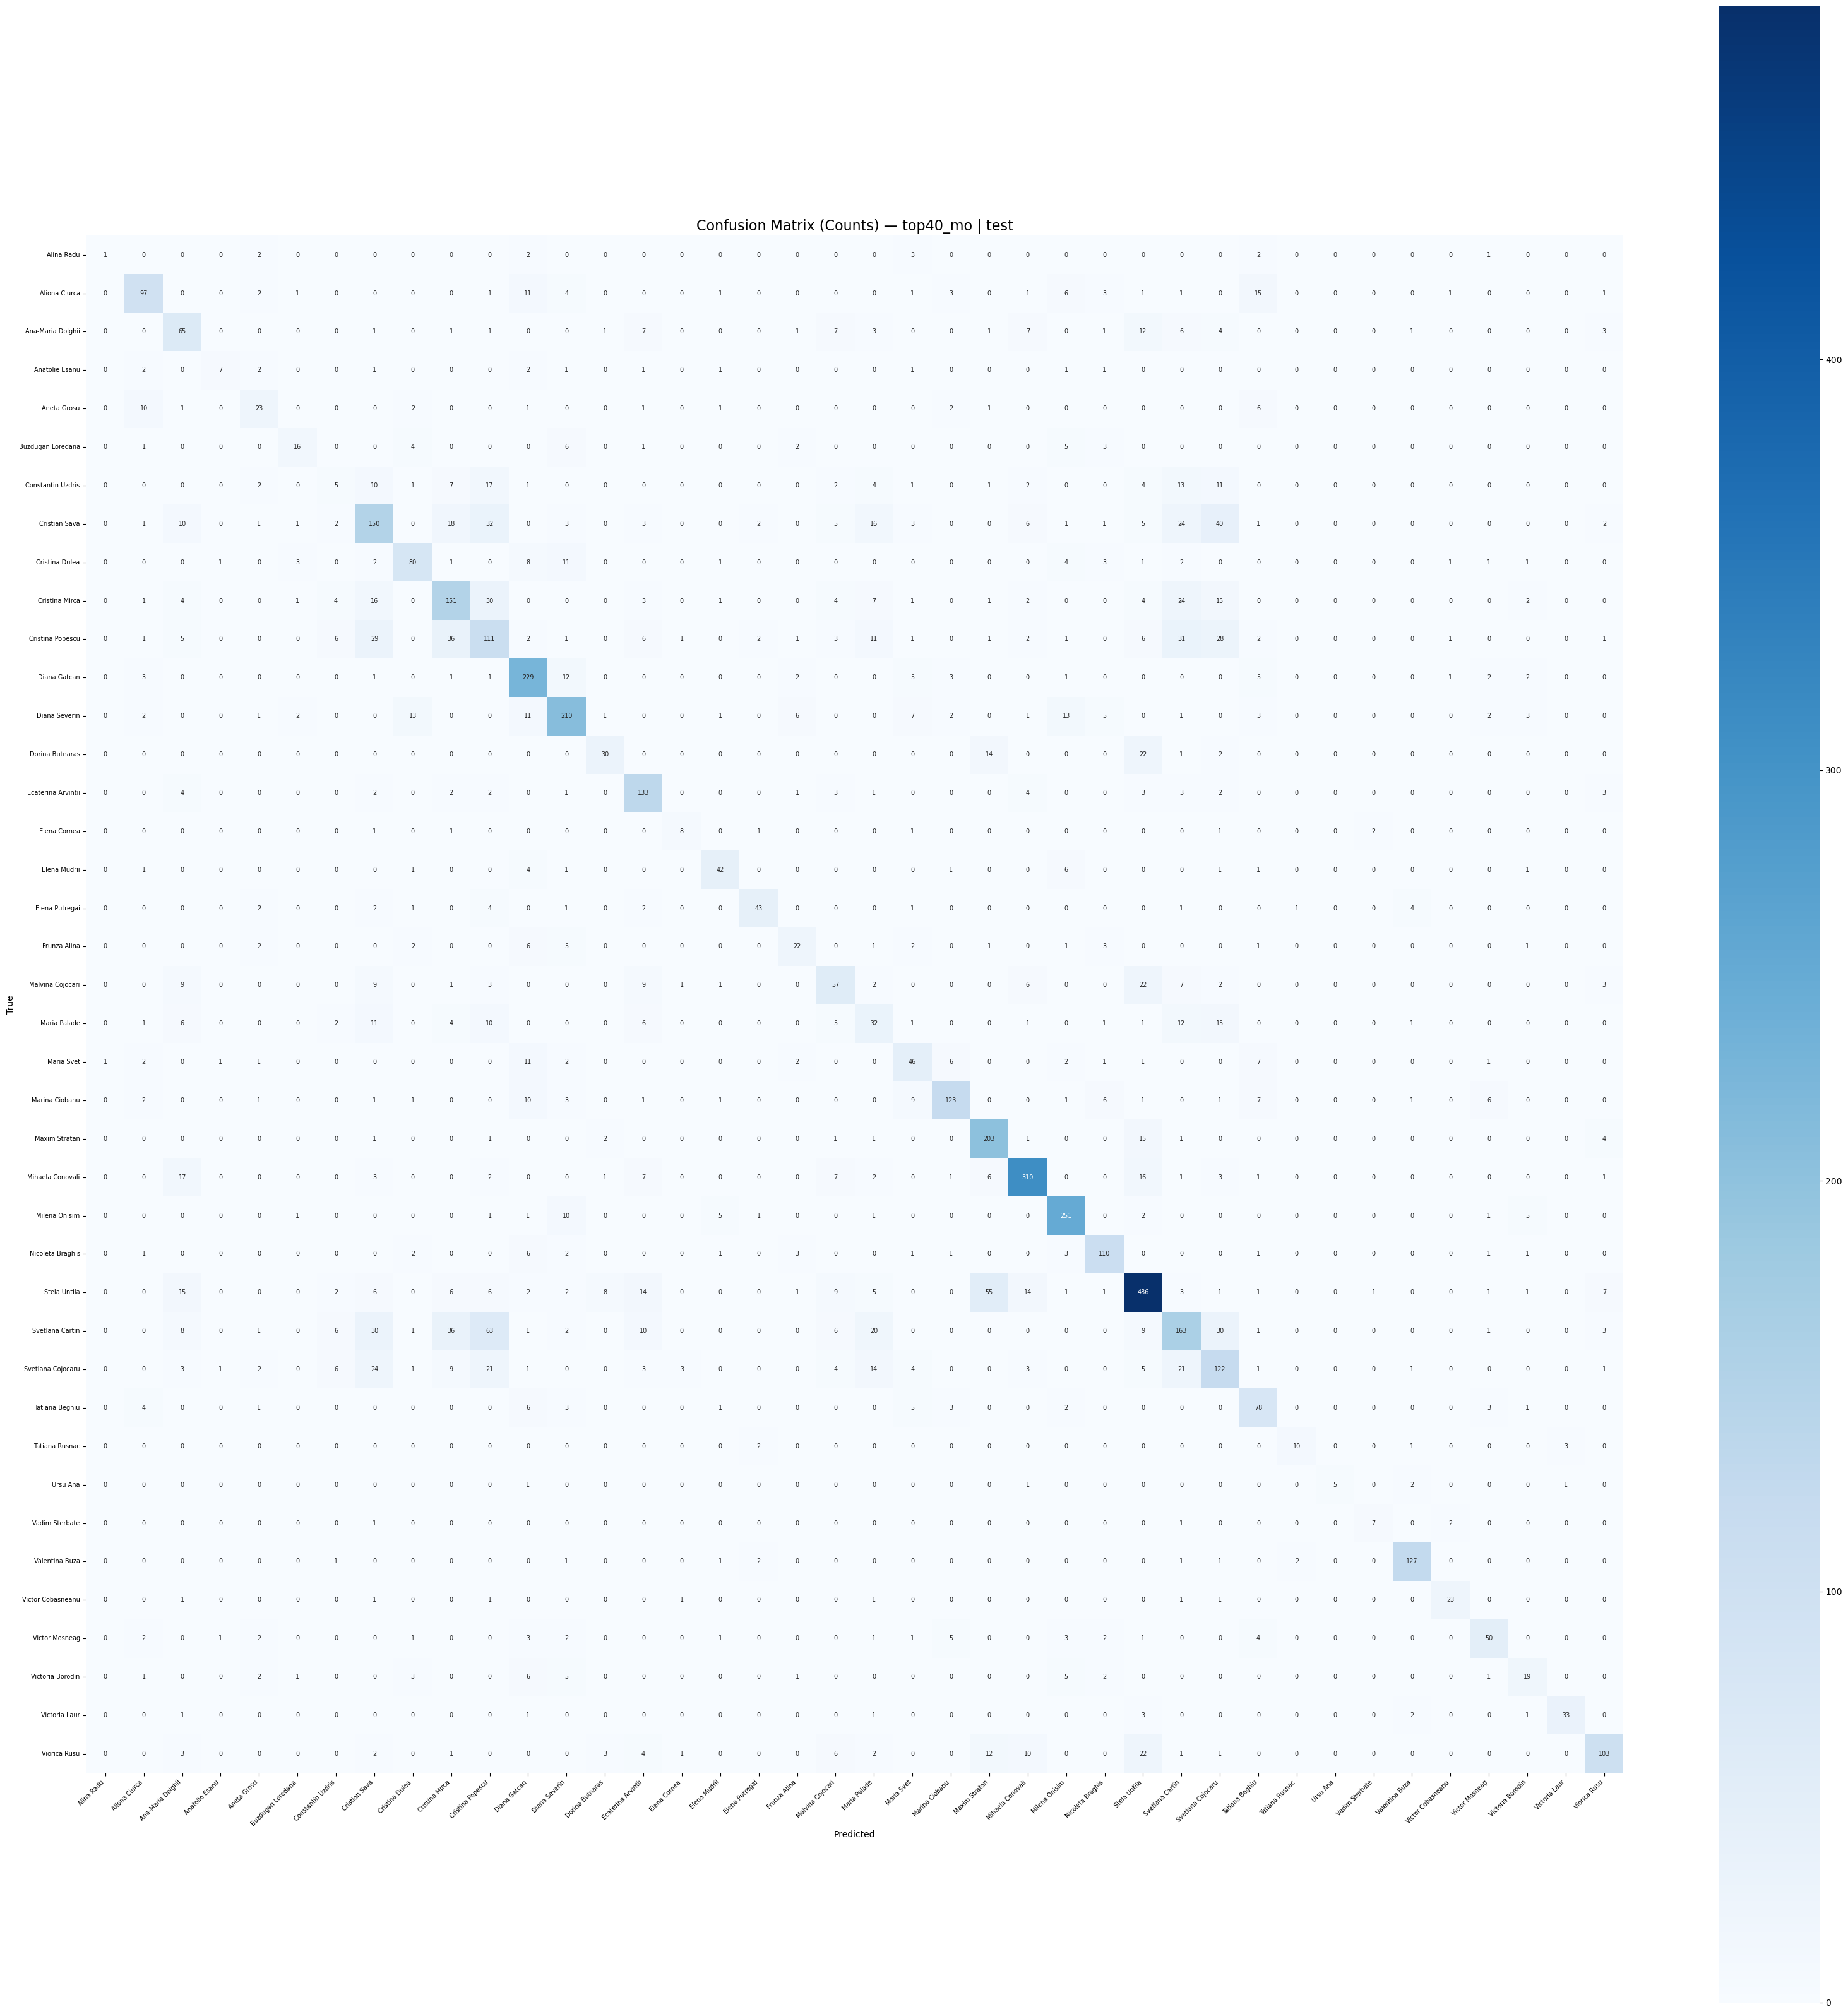

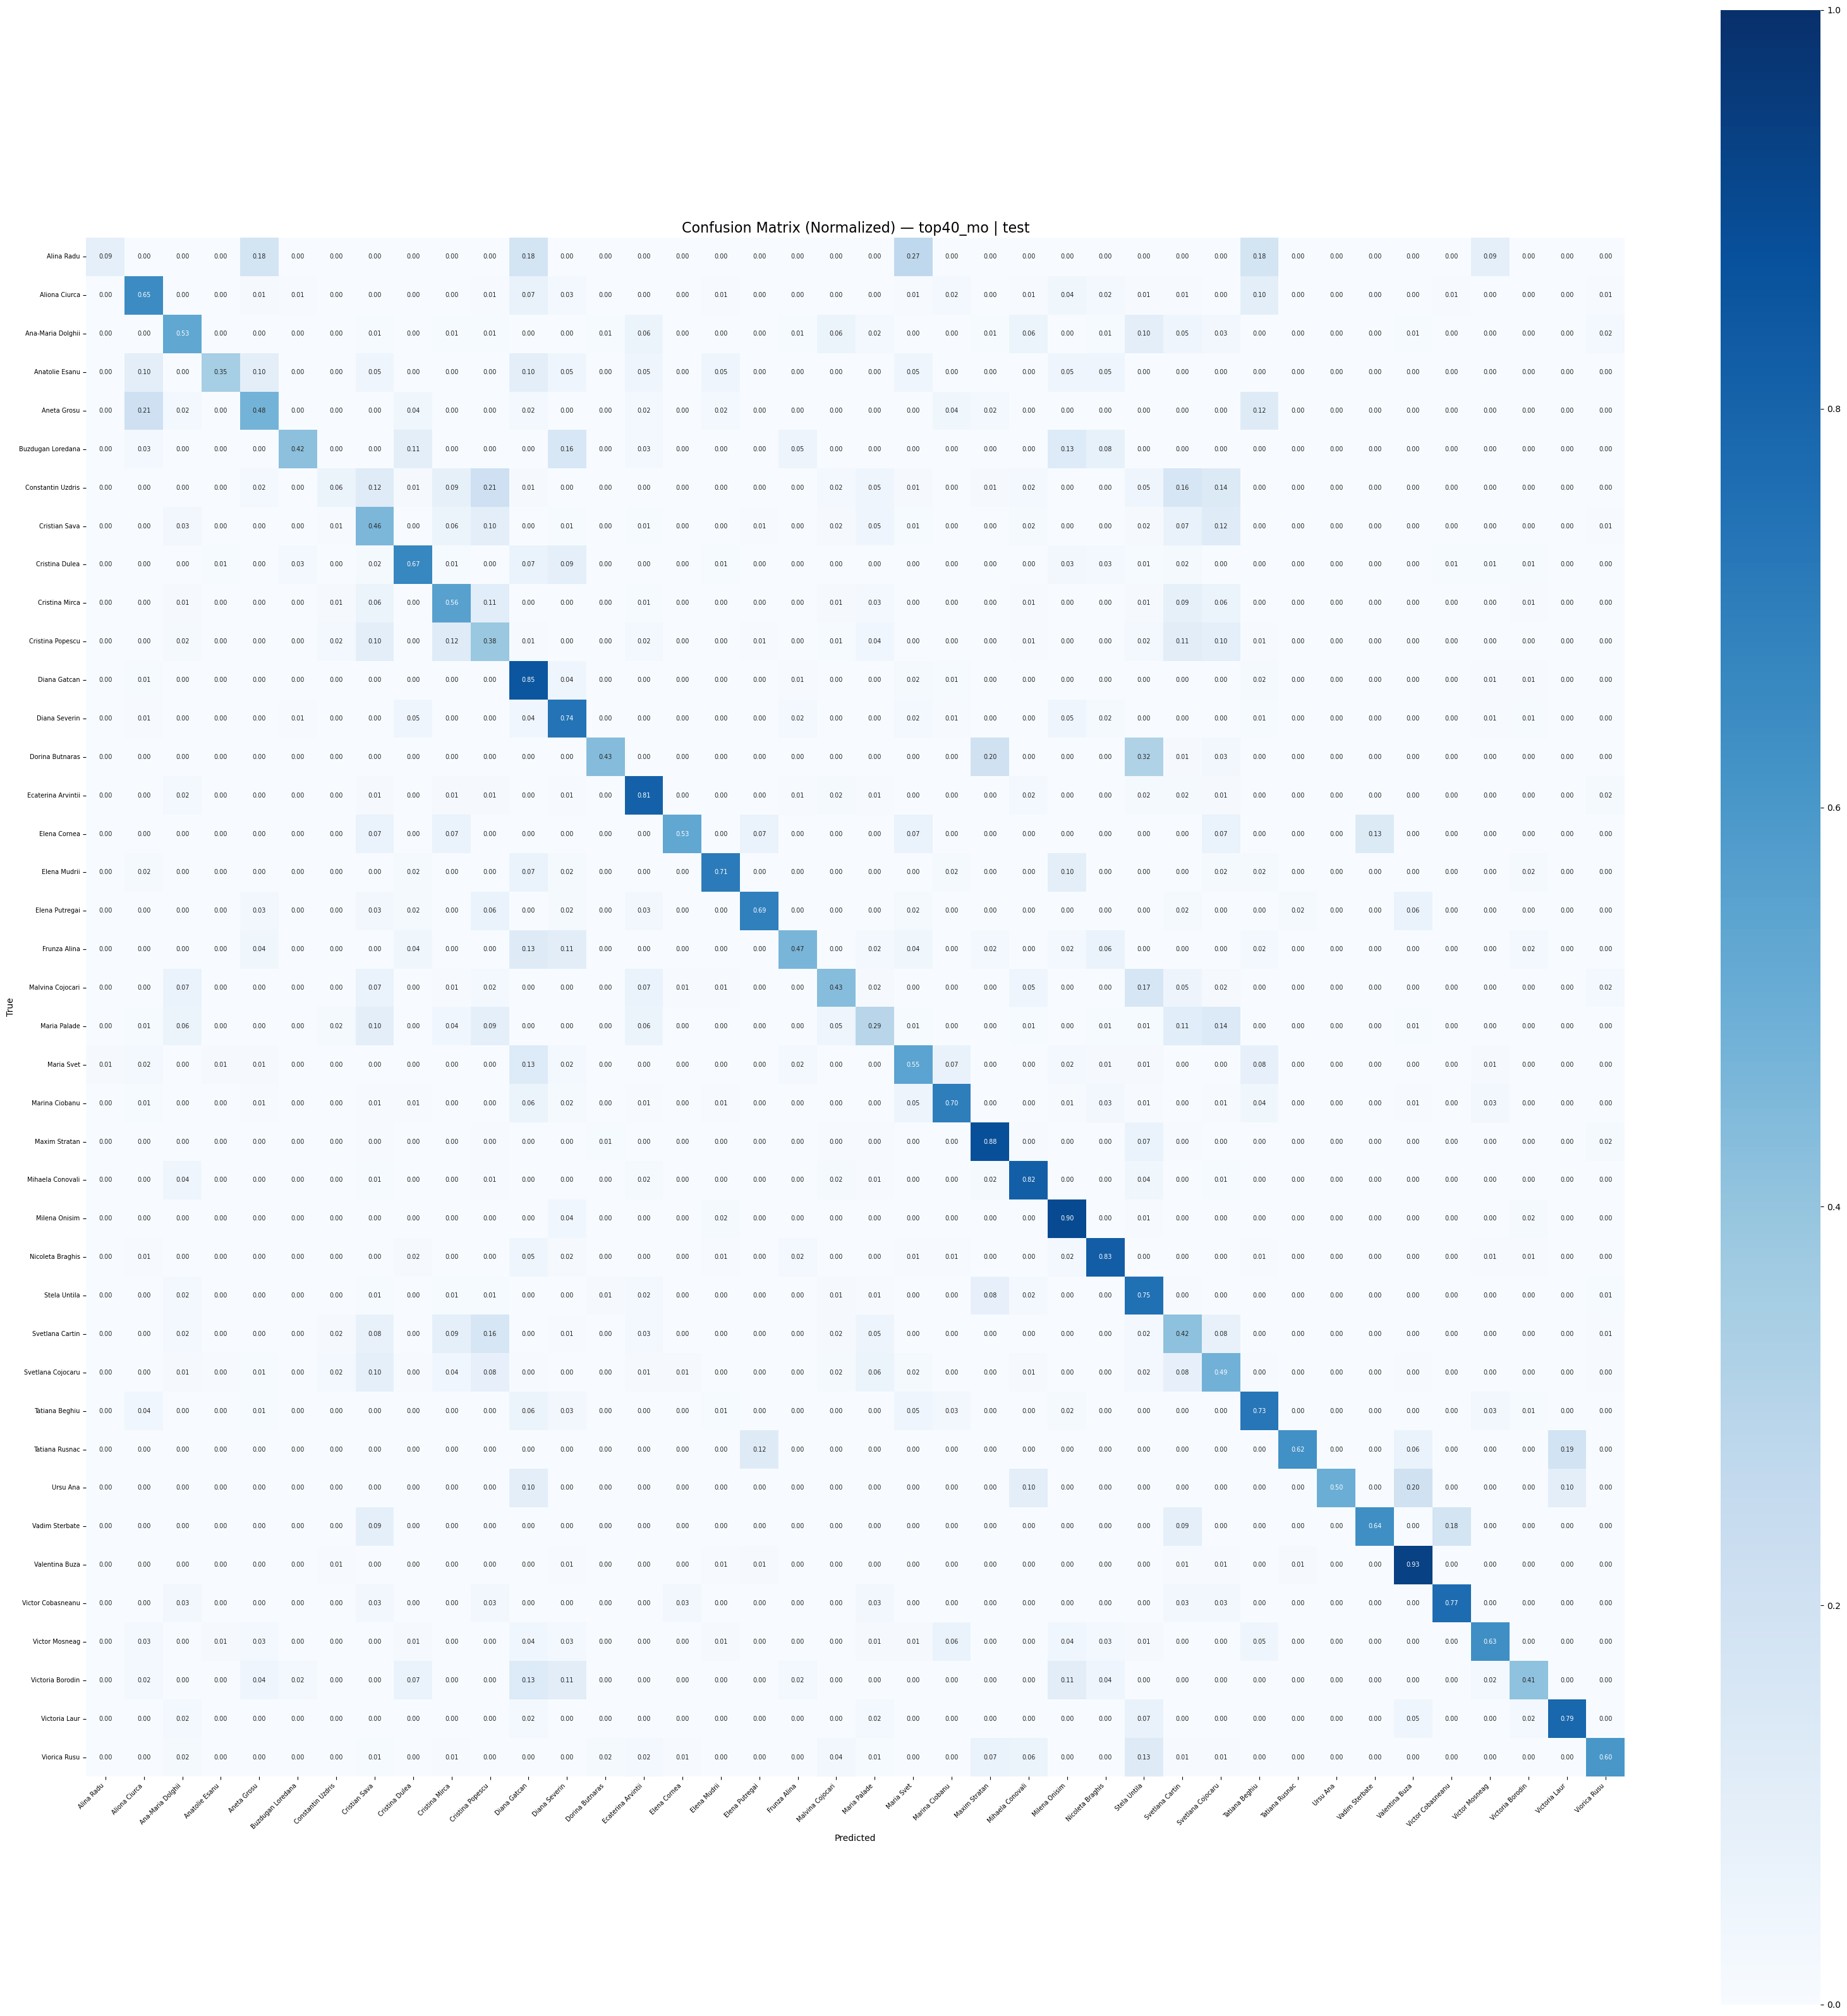

In [23]:
# confusion matrix
plot_confusion_matrix_bert(y_test_t40mo, preds_t40mo, le_t40mo, 'top40_mo', 'test', output_dir_4)

In [24]:
results = []

In [25]:
results.append({
    'Experiment': 'BERT Baseline',
    'dataset': 'top40_mo',
    'test_f1': round(f1_t40mo, 4),
    'test_acc': round(acc_t40mo, 4),
    'best val f1': round(history_t40mo['best_val_f1'], 4)
})


In [26]:
display(pd.DataFrame(results))

,Experiment,dataset,test_f1,test_acc,best val f1
0,BERT Baseline,top40_mo,0.6019,0.6406,0.6021


In [ ]:
output_file_40mo = f'{output_dir_4}/results.json'
with open(output_file_40mo, 'w') as f:
    json.dump(results, f, indent=2)

,Experiment,dataset,test_f1,test_acc,best val f1
0,BERT Baseline,top20_ro,0.6303,0.6368,1.0
1,BERT Baseline,top40_ro,0.6170,0.6127,NaN


In [34]:
import os
import json

os.makedirs('results_baseline', exist_ok=True)
path = os.path.join('results_baseline', 'results_baseline.json')

if os.path.exists(path):
    with open(path, 'r', encoding='utf-8') as f:
        existing = json.load(f)
else:
    existing = []

display(pd.DataFrame(existing))
existing.extend(results)

with open(path, 'w', encoding='utf-8') as f:
    json.dump(existing, f, indent=2, ensure_ascii=False)

display(pd.DataFrame(existing))
# sa nu uiti sa iei din output pt ro4o si ro20 best val f1 

,Experiment,dataset,test_f1,test_acc,best val f1
0,BERT Baseline,top20_ro,0.630300,0.636800,0.628200
1,BERT Baseline,top40_ro,0.617000,0.612700,0.616300
2,BERT Baseline,top20_mo,0.675500,0.676600,0.688100
3,BERT Baseline,top40_mo,0.588456,0.630973,0.601305


,Experiment,dataset,test_f1,test_acc,best val f1
0,BERT Baseline,top20_ro,0.630300,0.636800,0.628200
1,BERT Baseline,top40_ro,0.617000,0.612700,0.616300
2,BERT Baseline,top20_mo,0.675500,0.676600,0.688100
3,BERT Baseline,top40_mo,0.588456,0.630973,0.601305
4,BERT Baseline,top20_mo,0.675500,0.676600,0.688100
5,BERT Baseline,top40_mo,0.588500,0.631000,0.601300
